<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/Evaluasi_hasil_simulasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mounted at /content/drive
OK: WEAK — GRID20 dan GRID30
OK: MODERATE — GRID20 dan GRID30
OK: STRONG — GRID20 dan GRID30


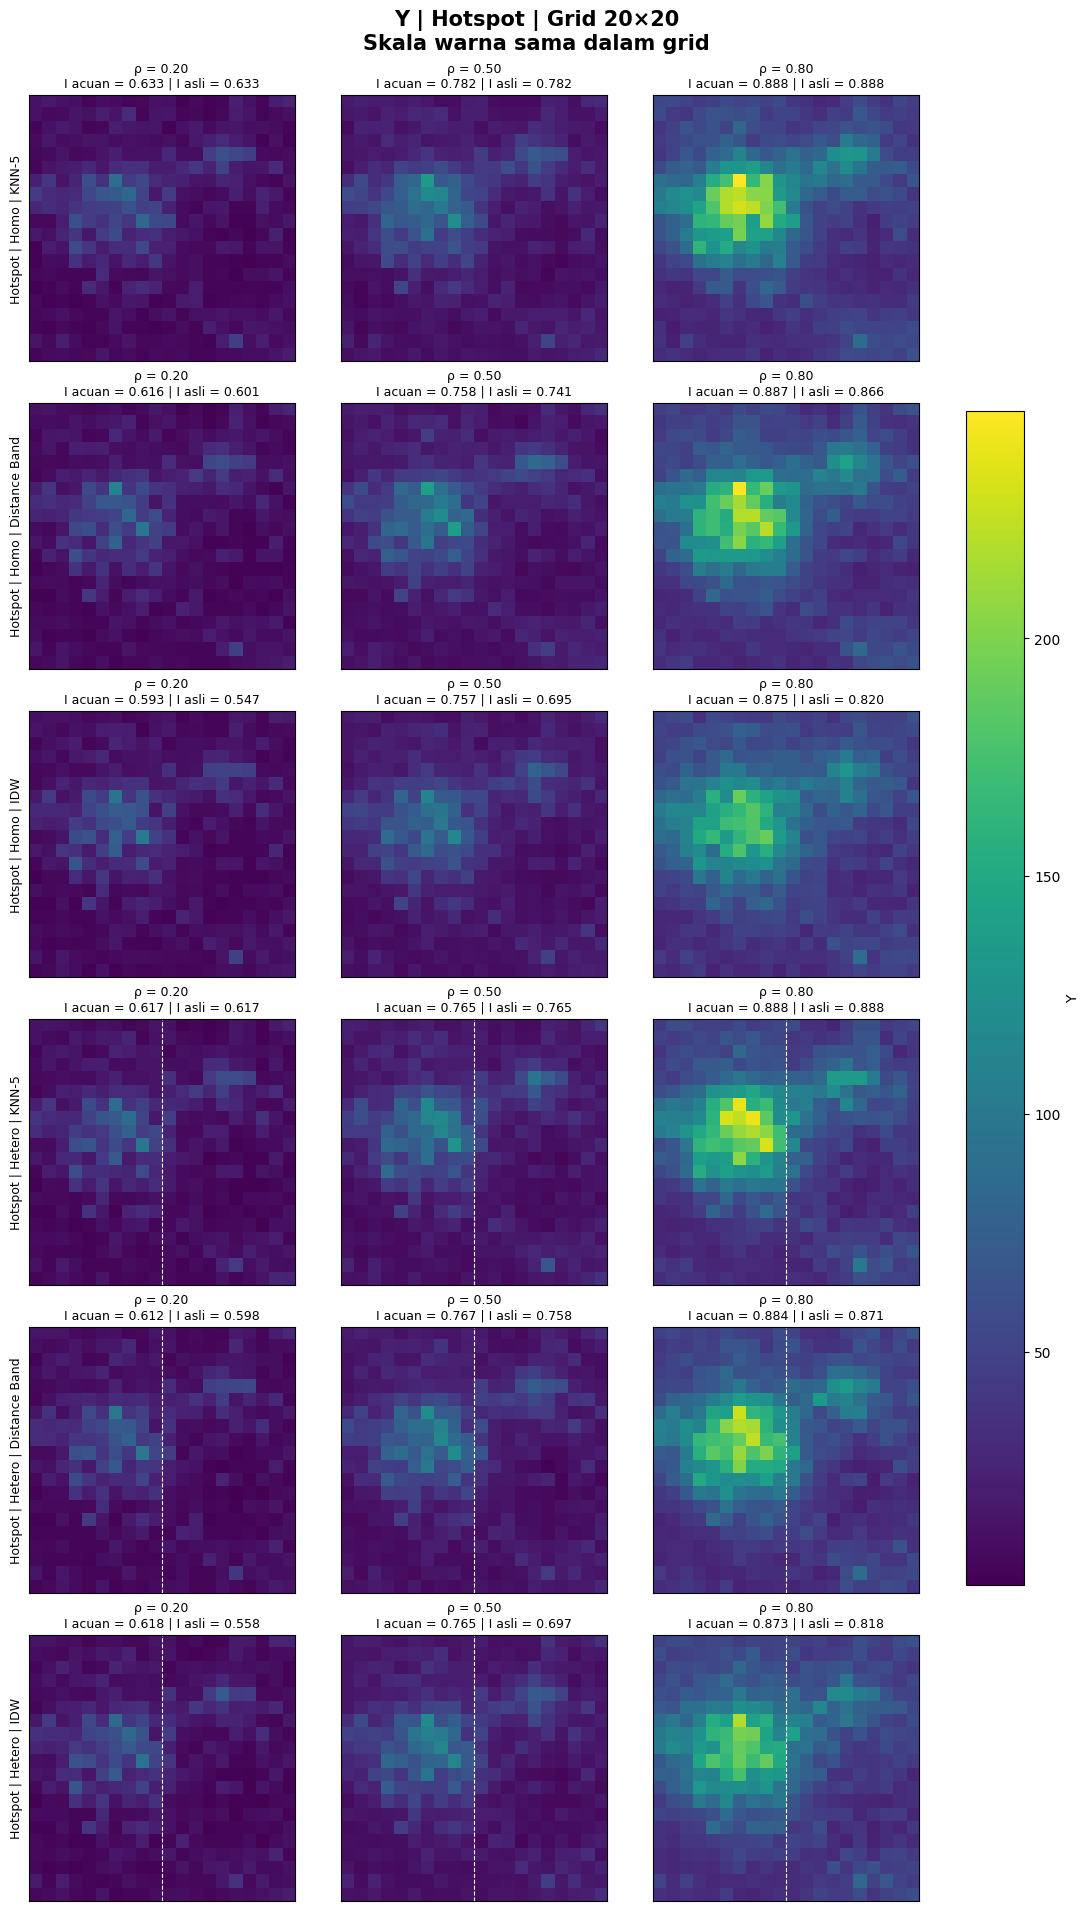

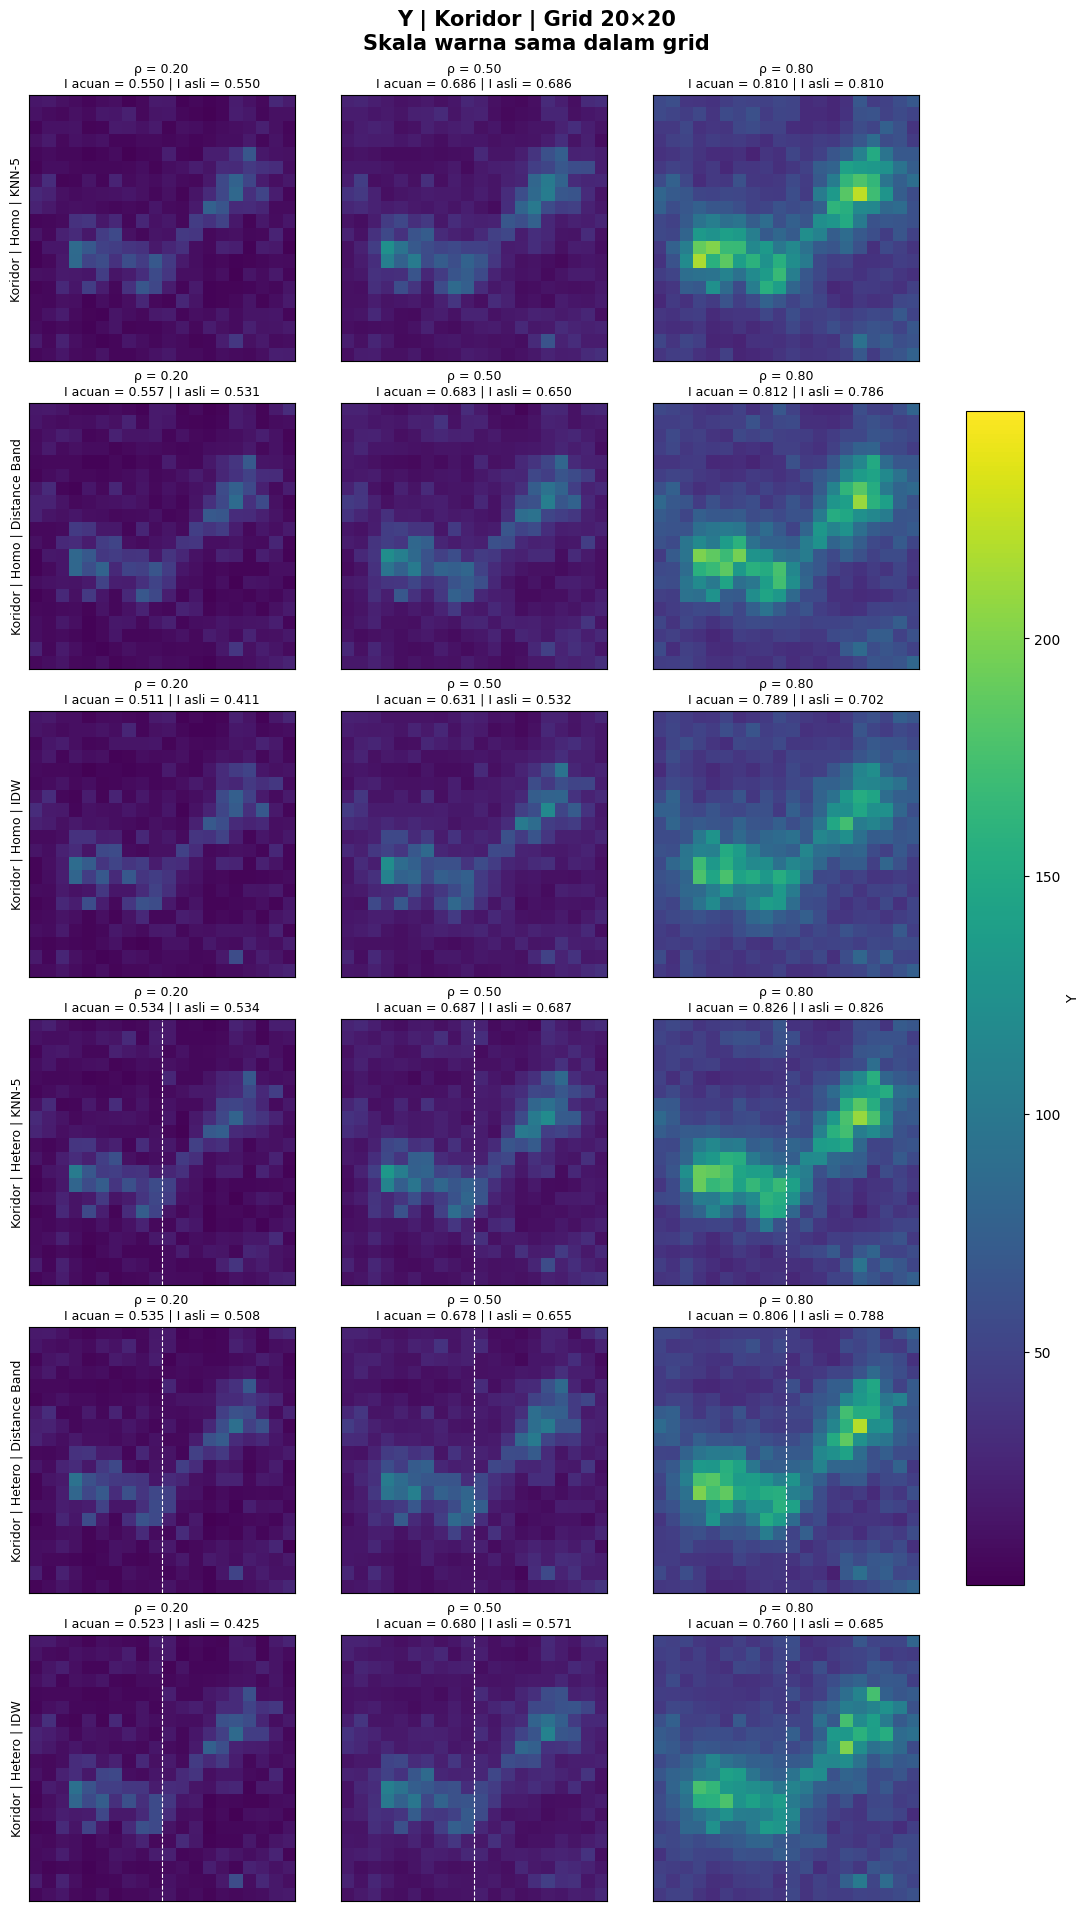

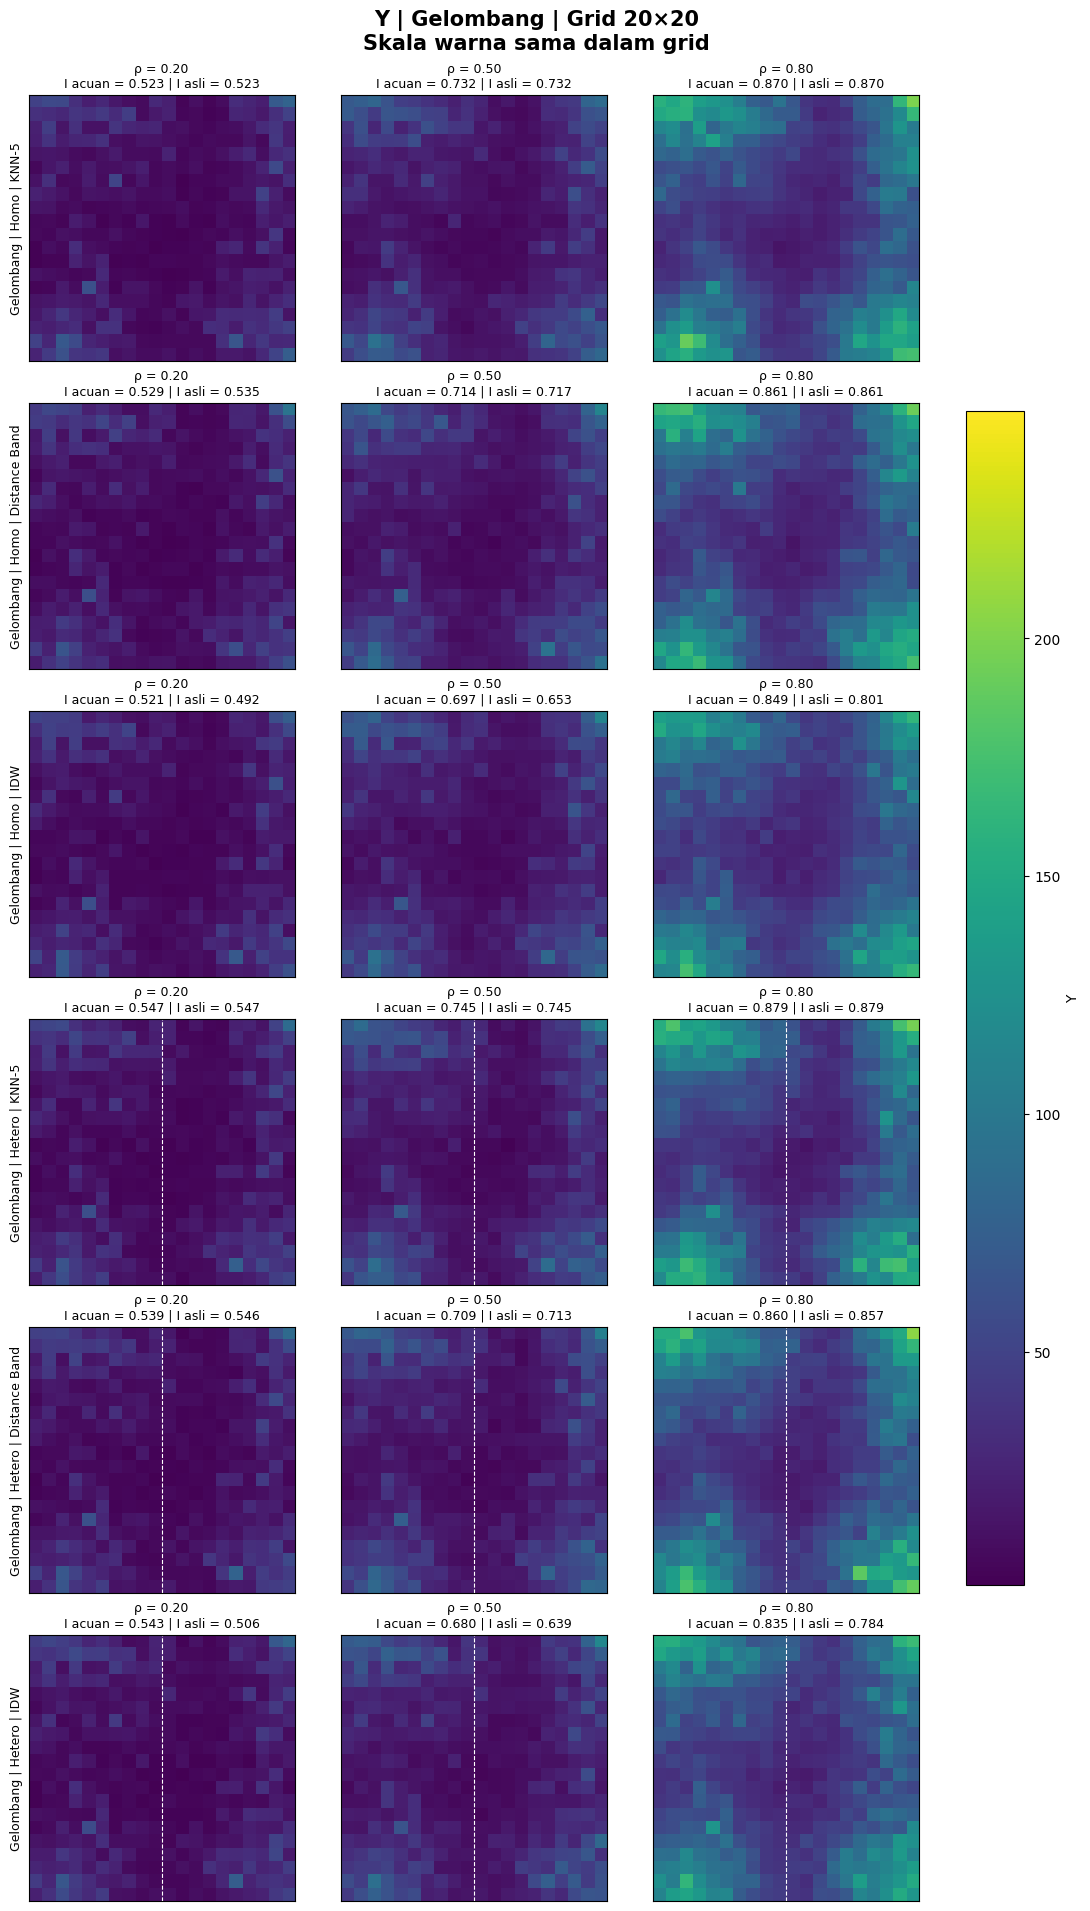

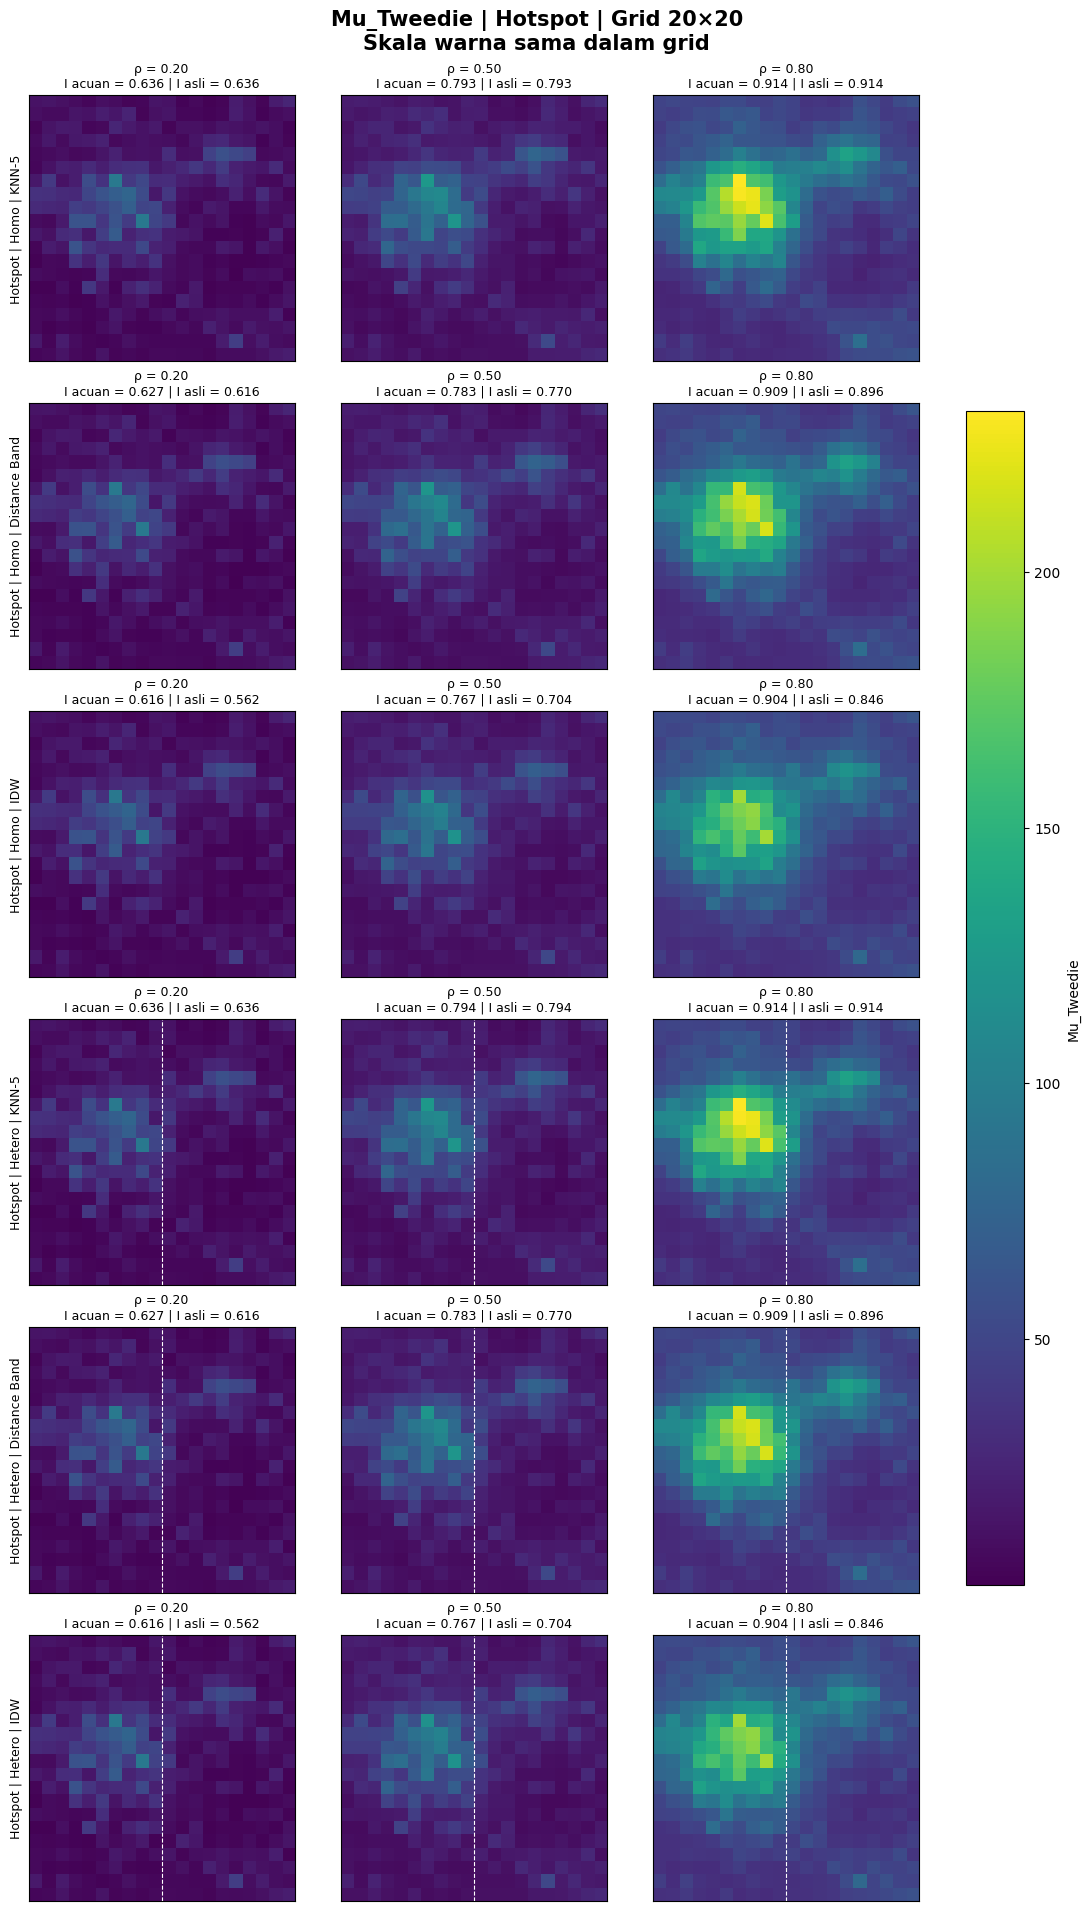

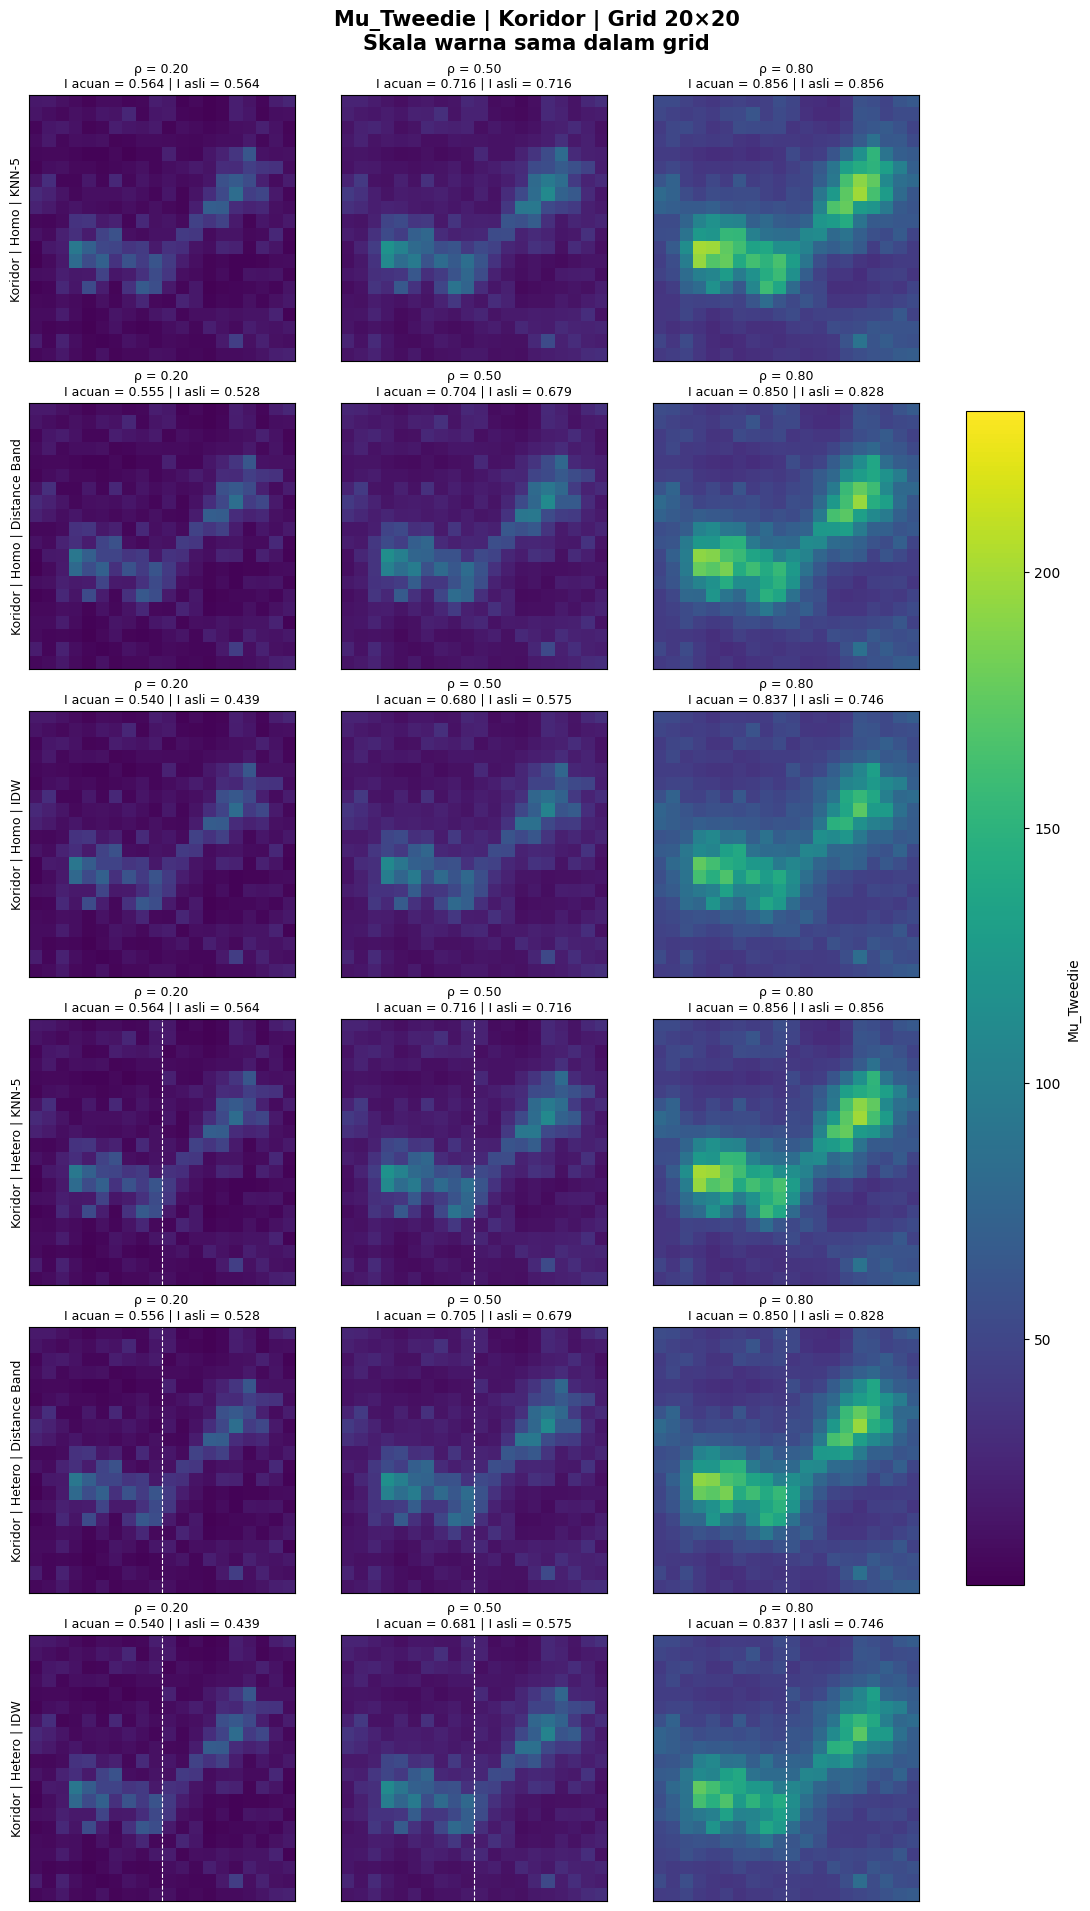

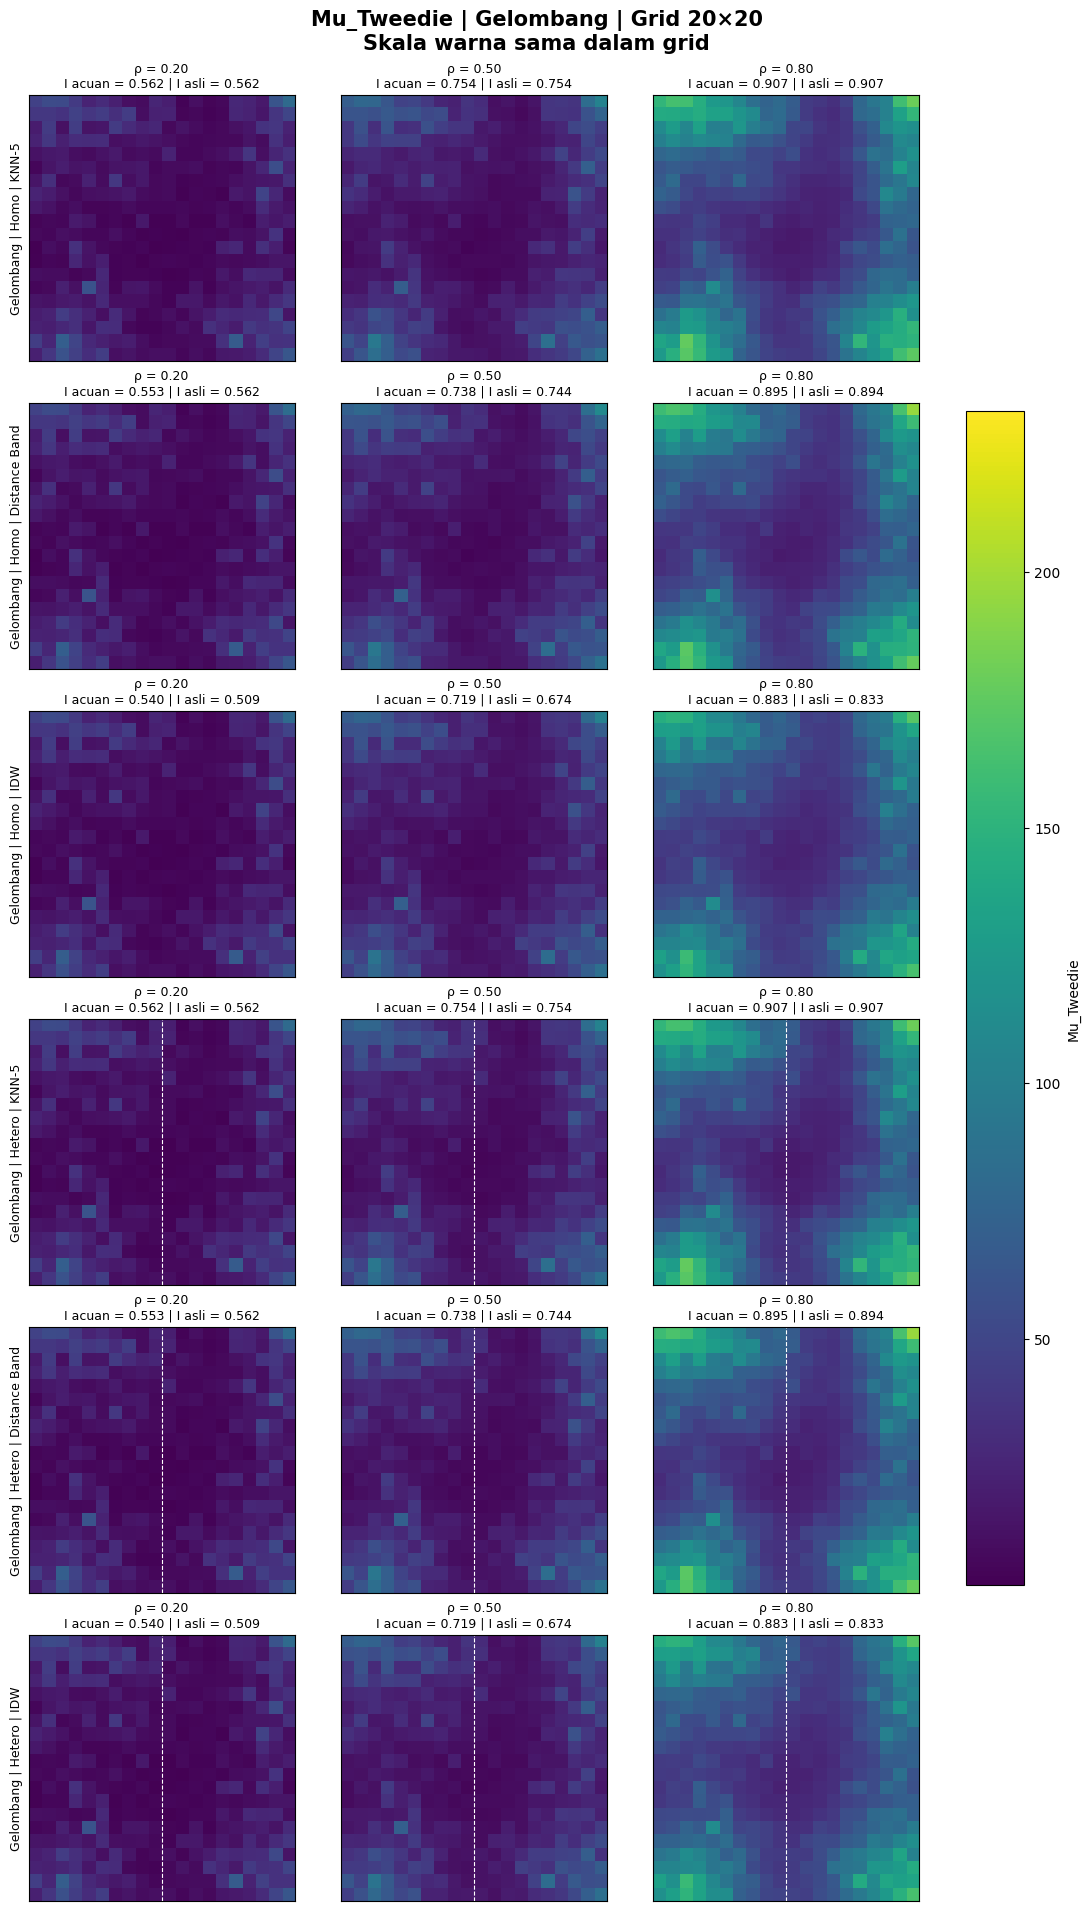

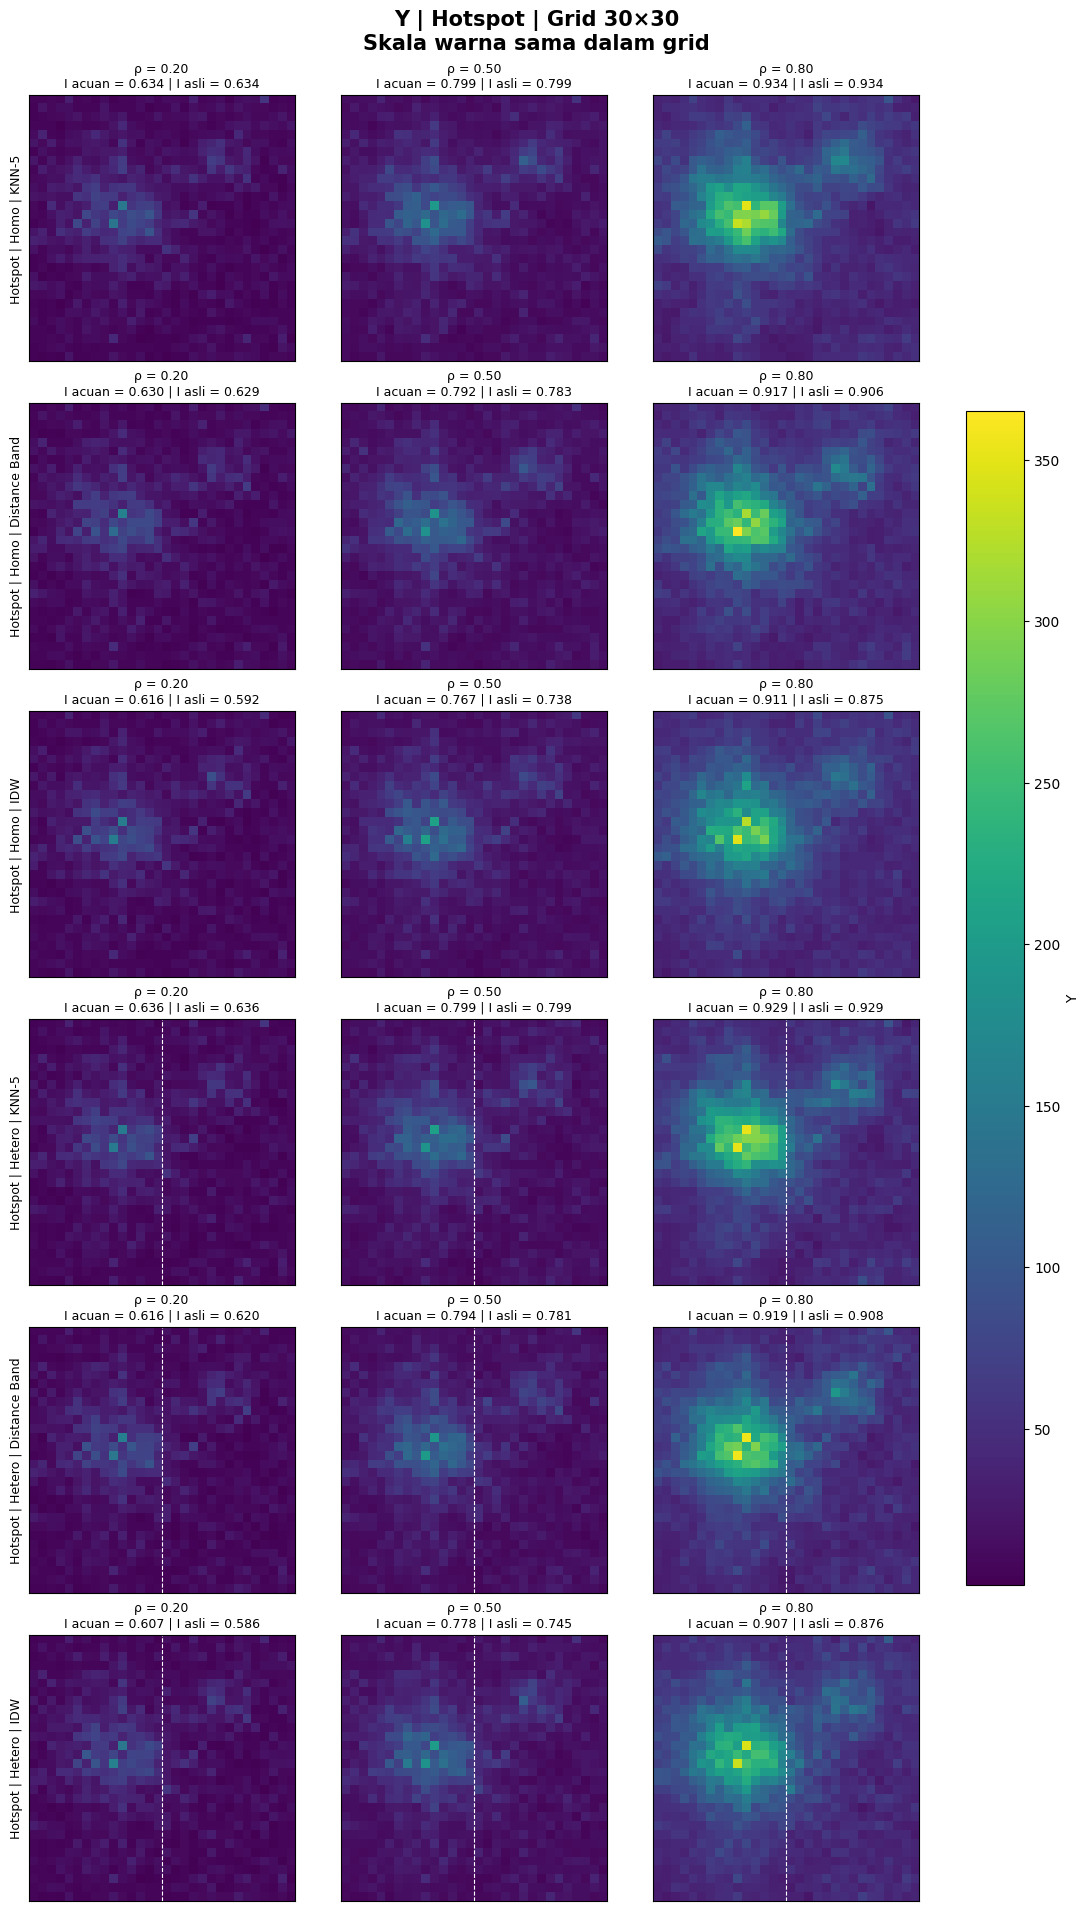

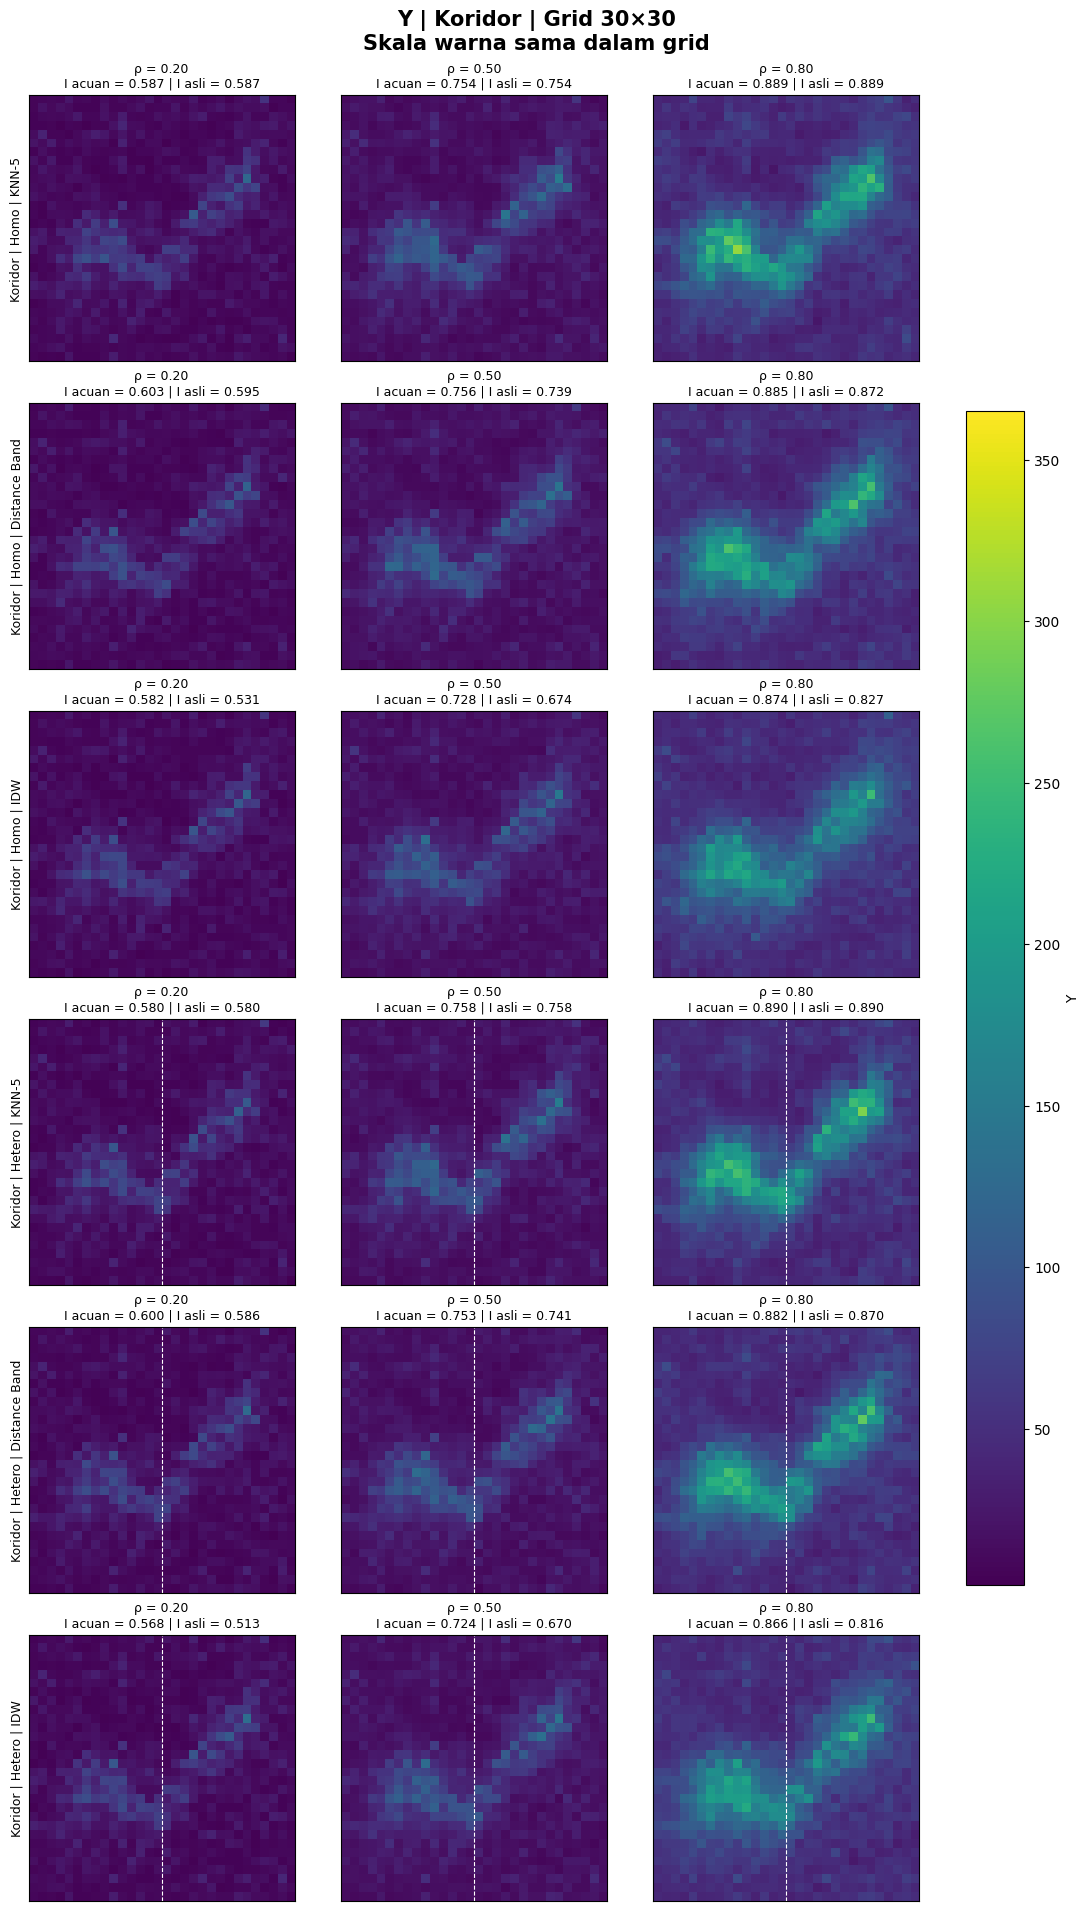

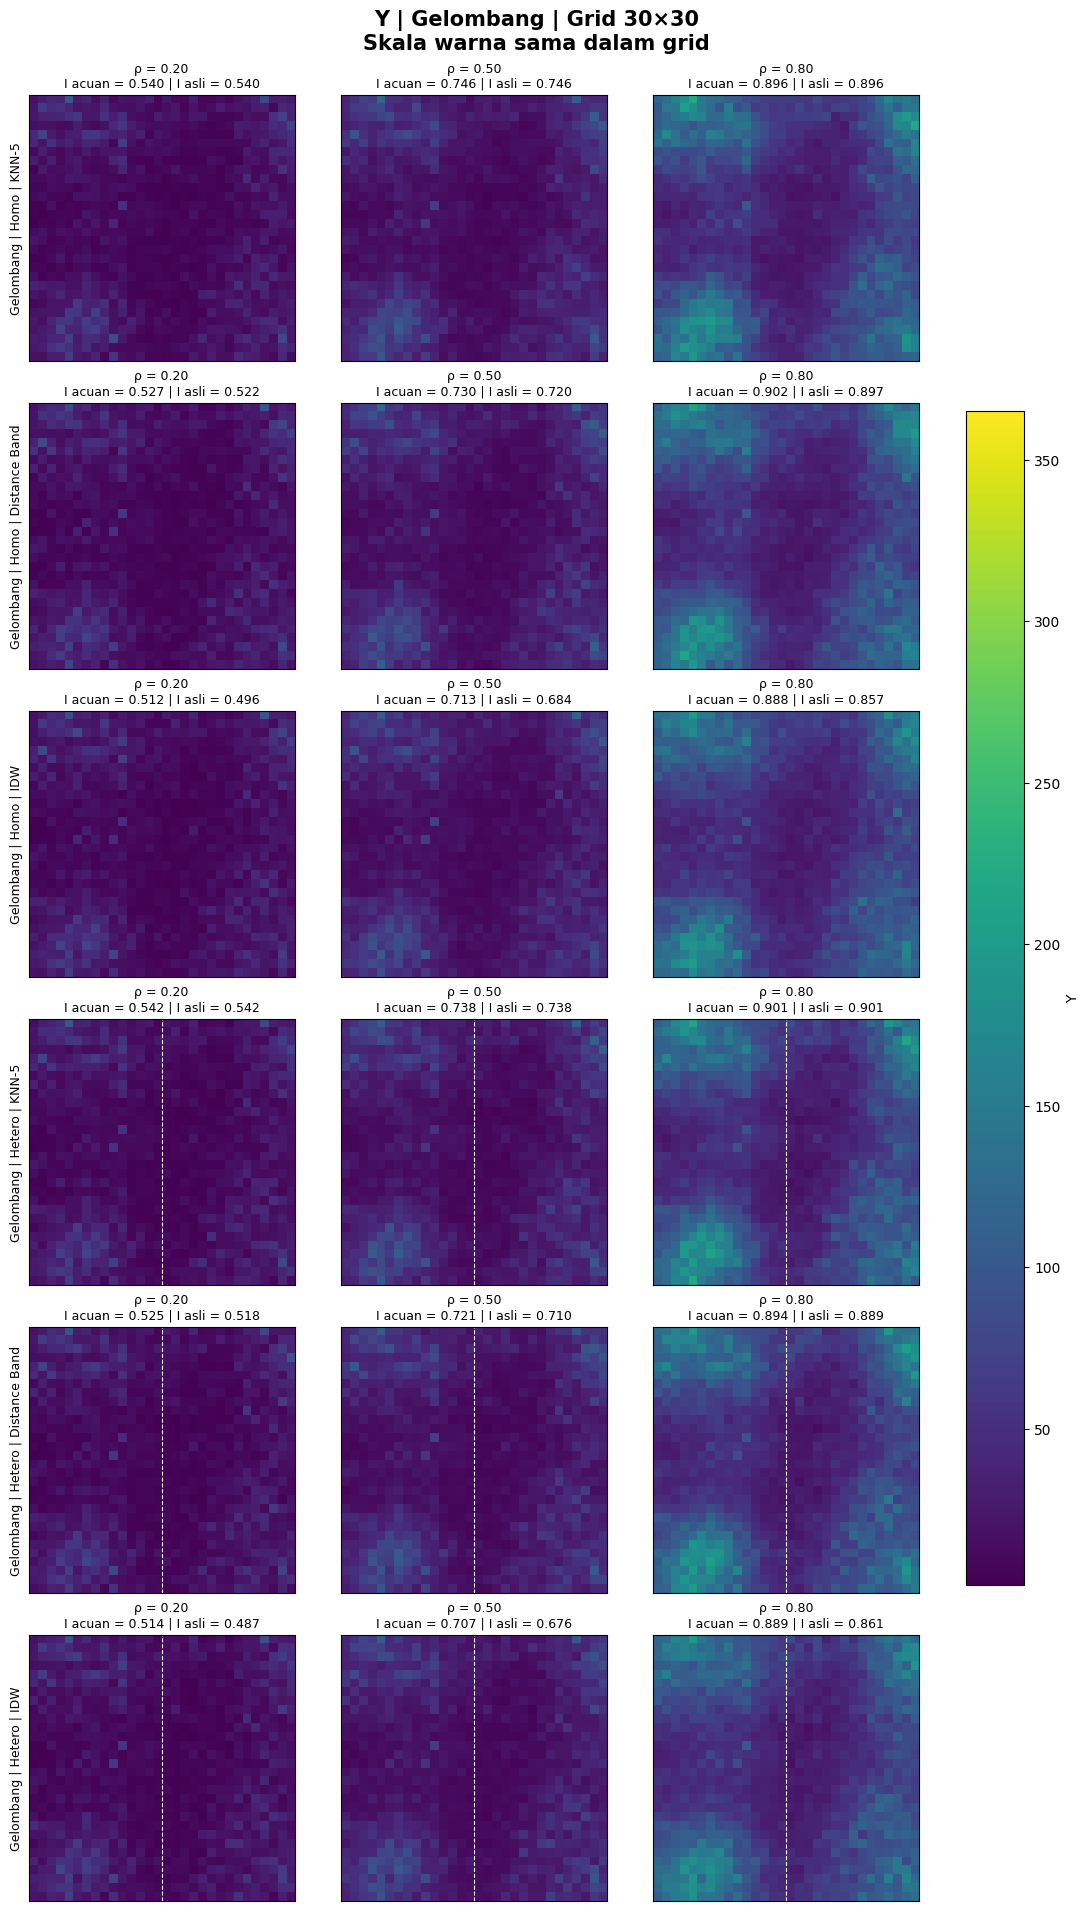

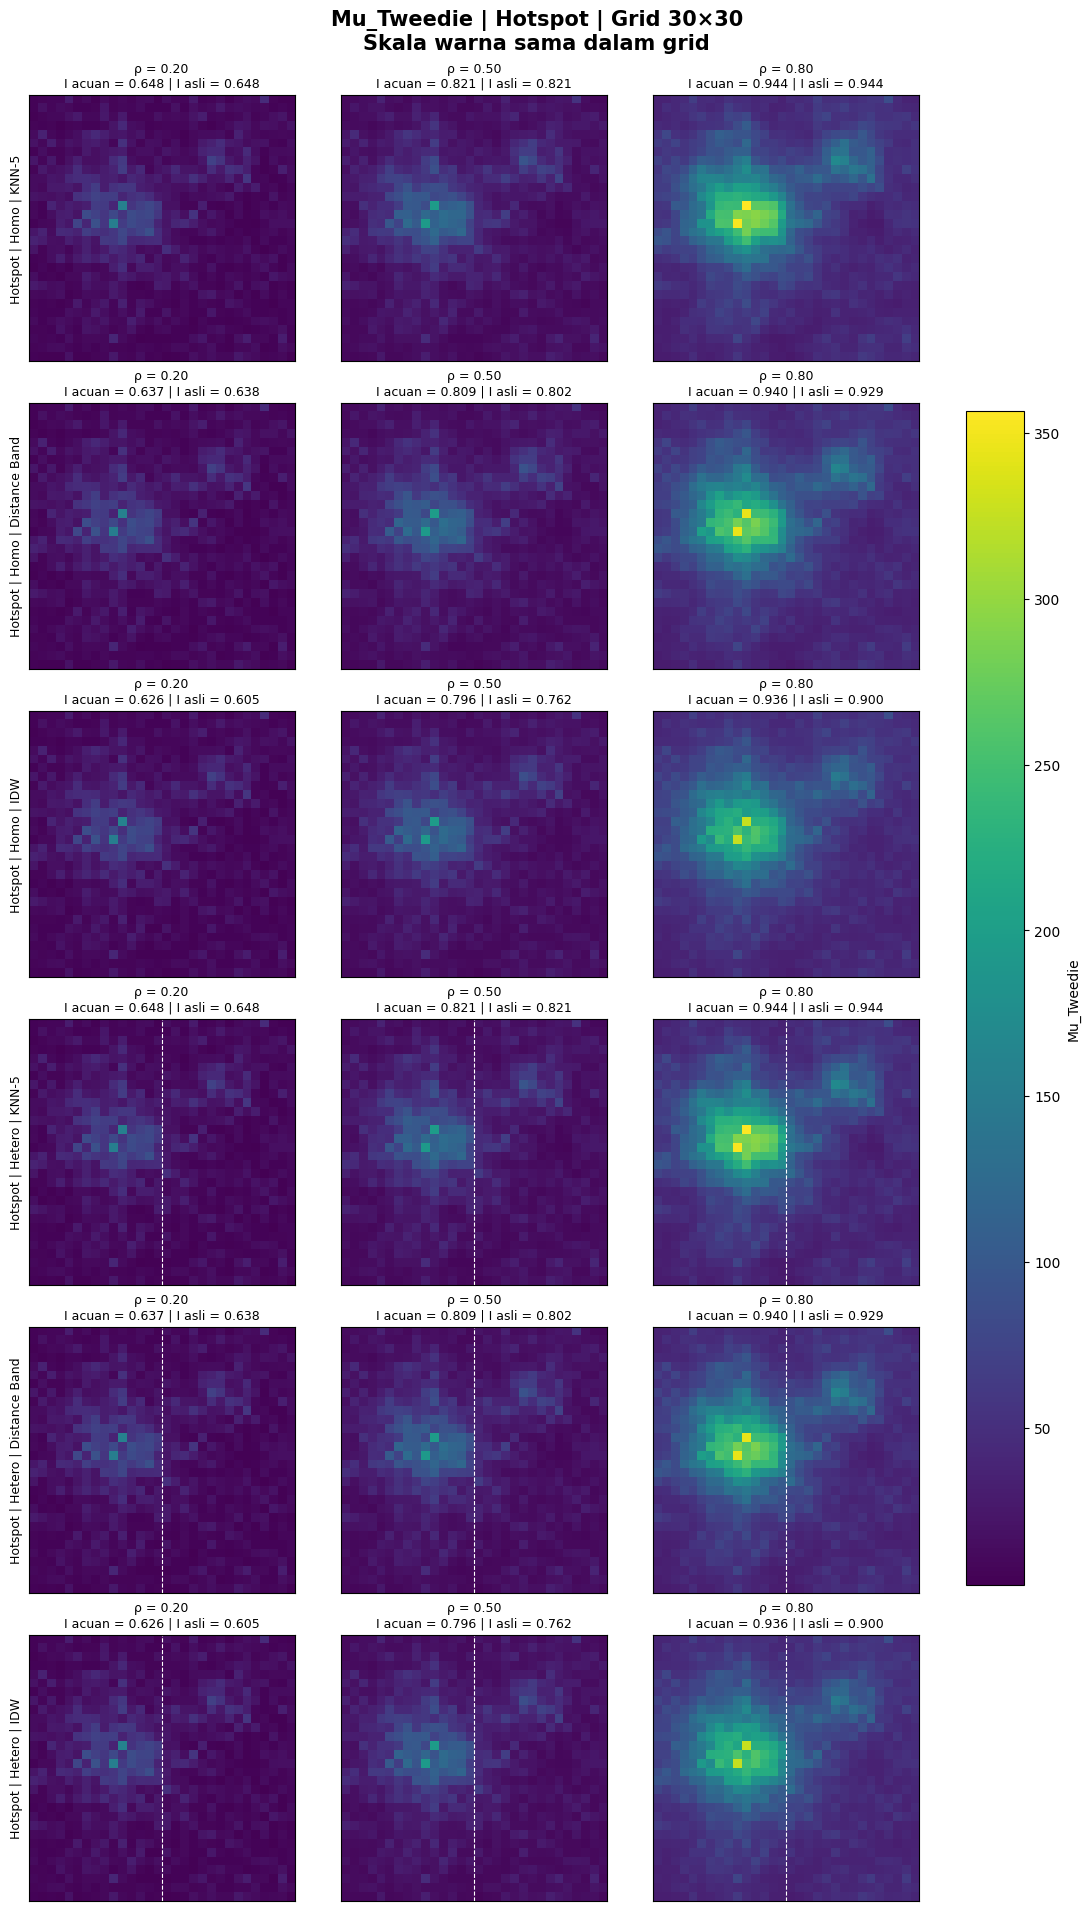

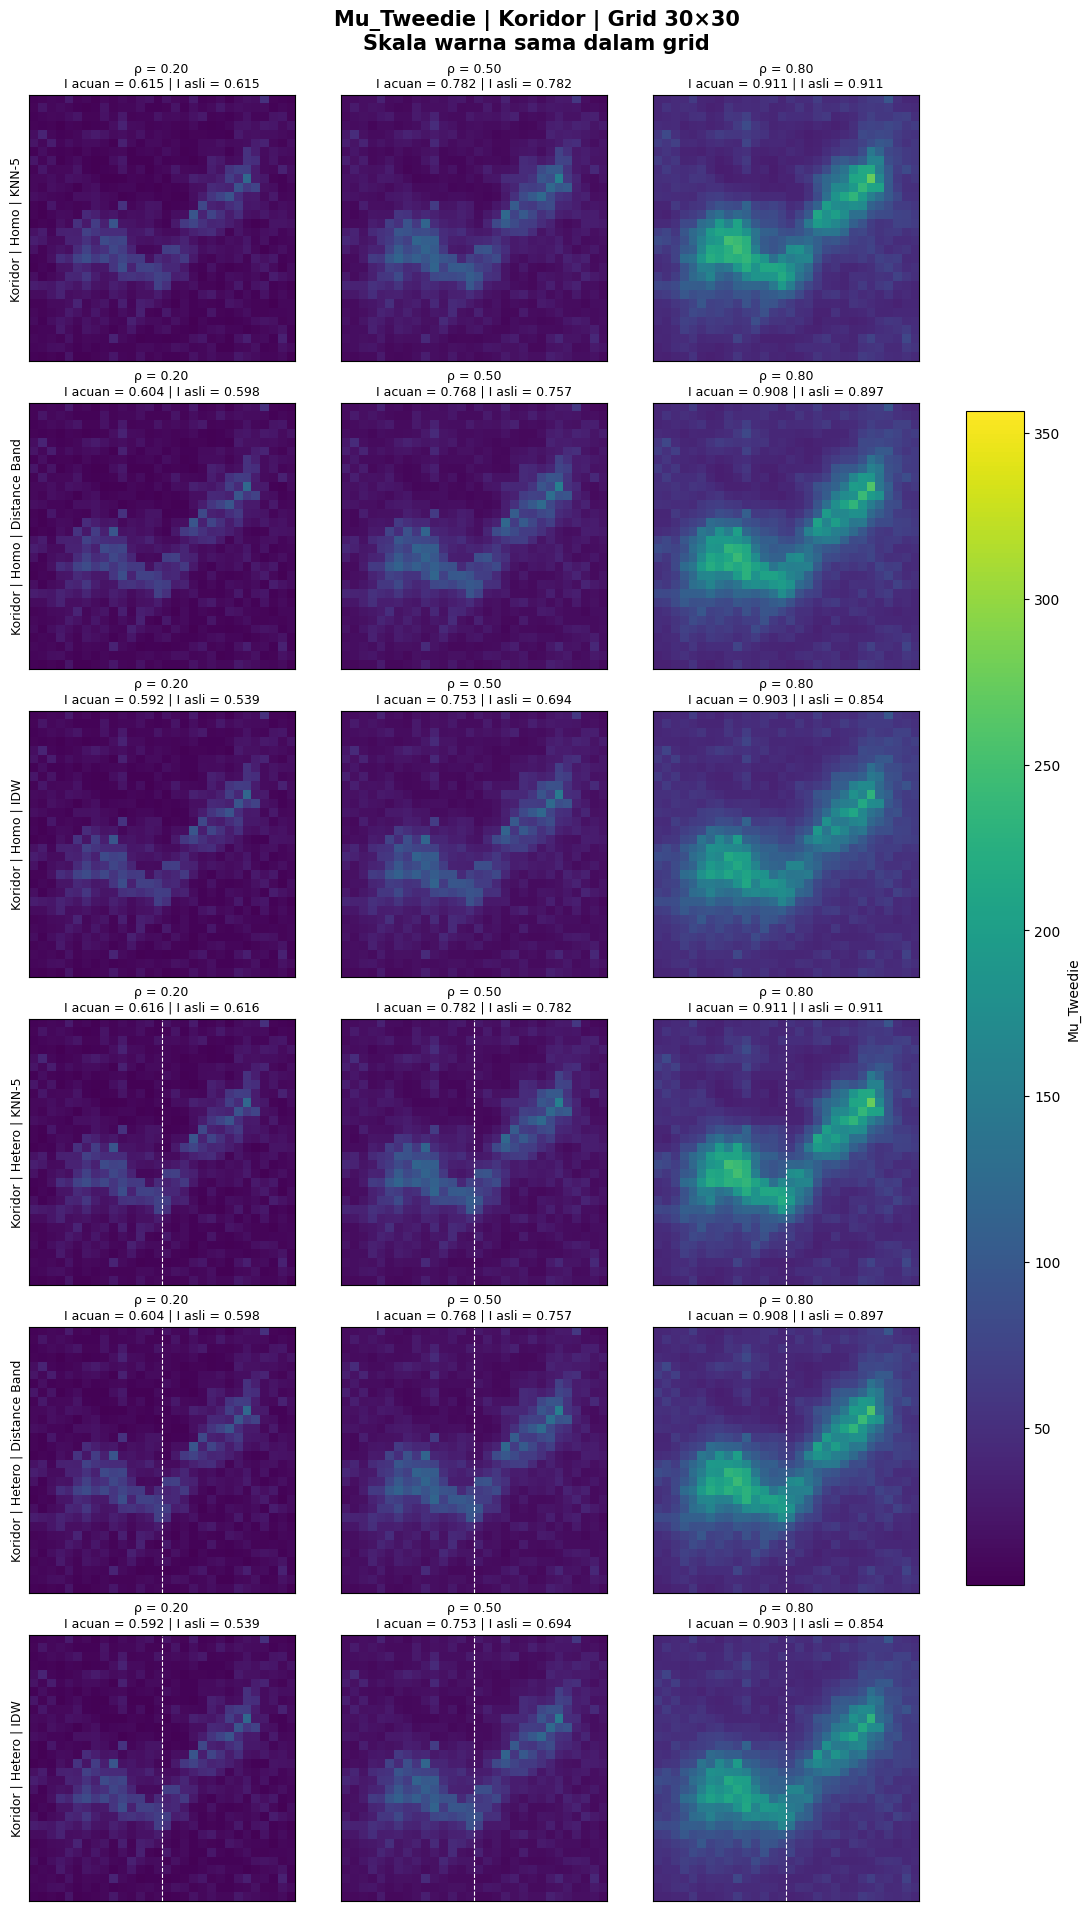

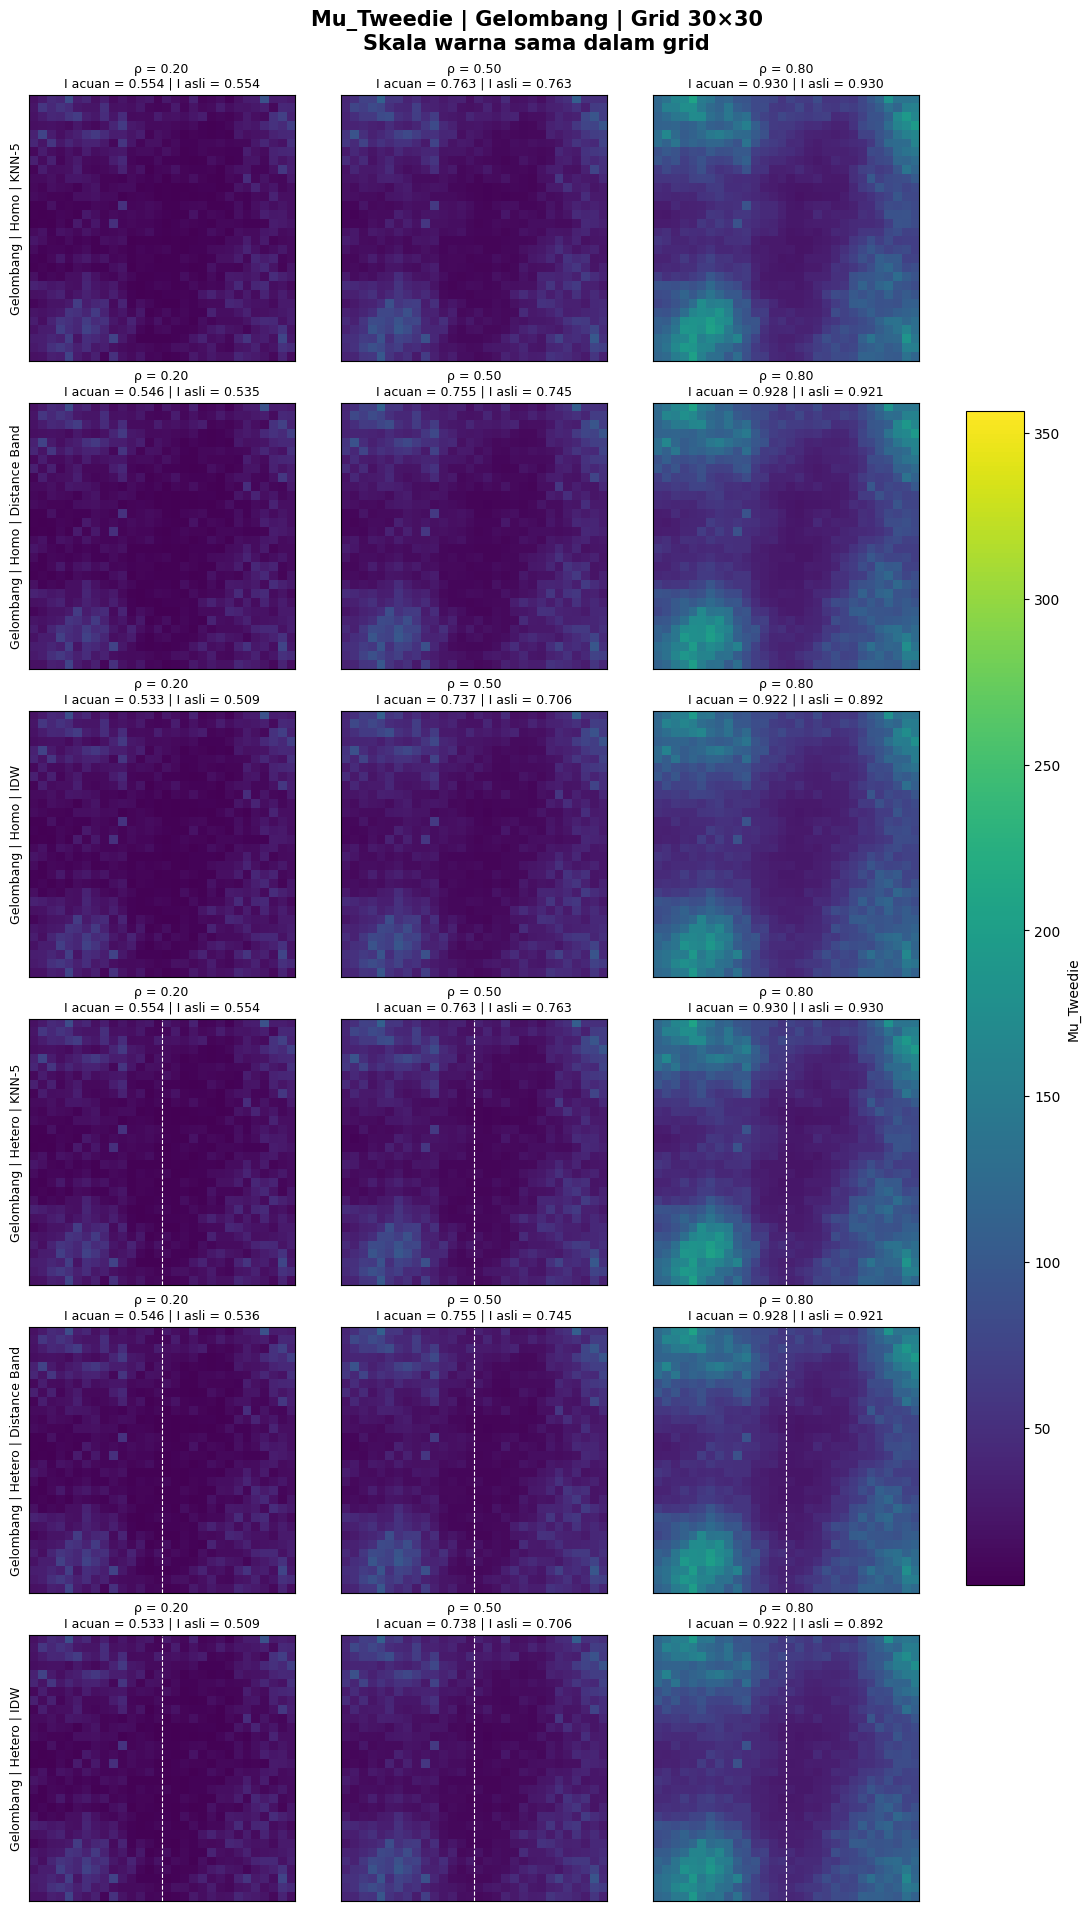

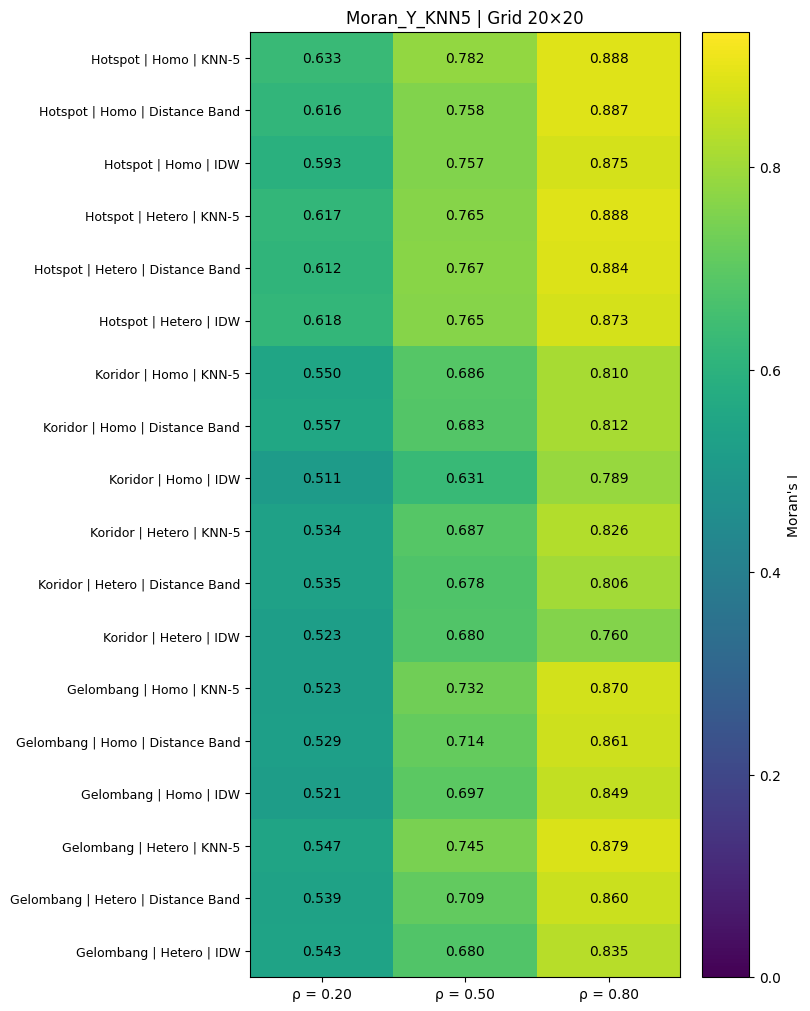

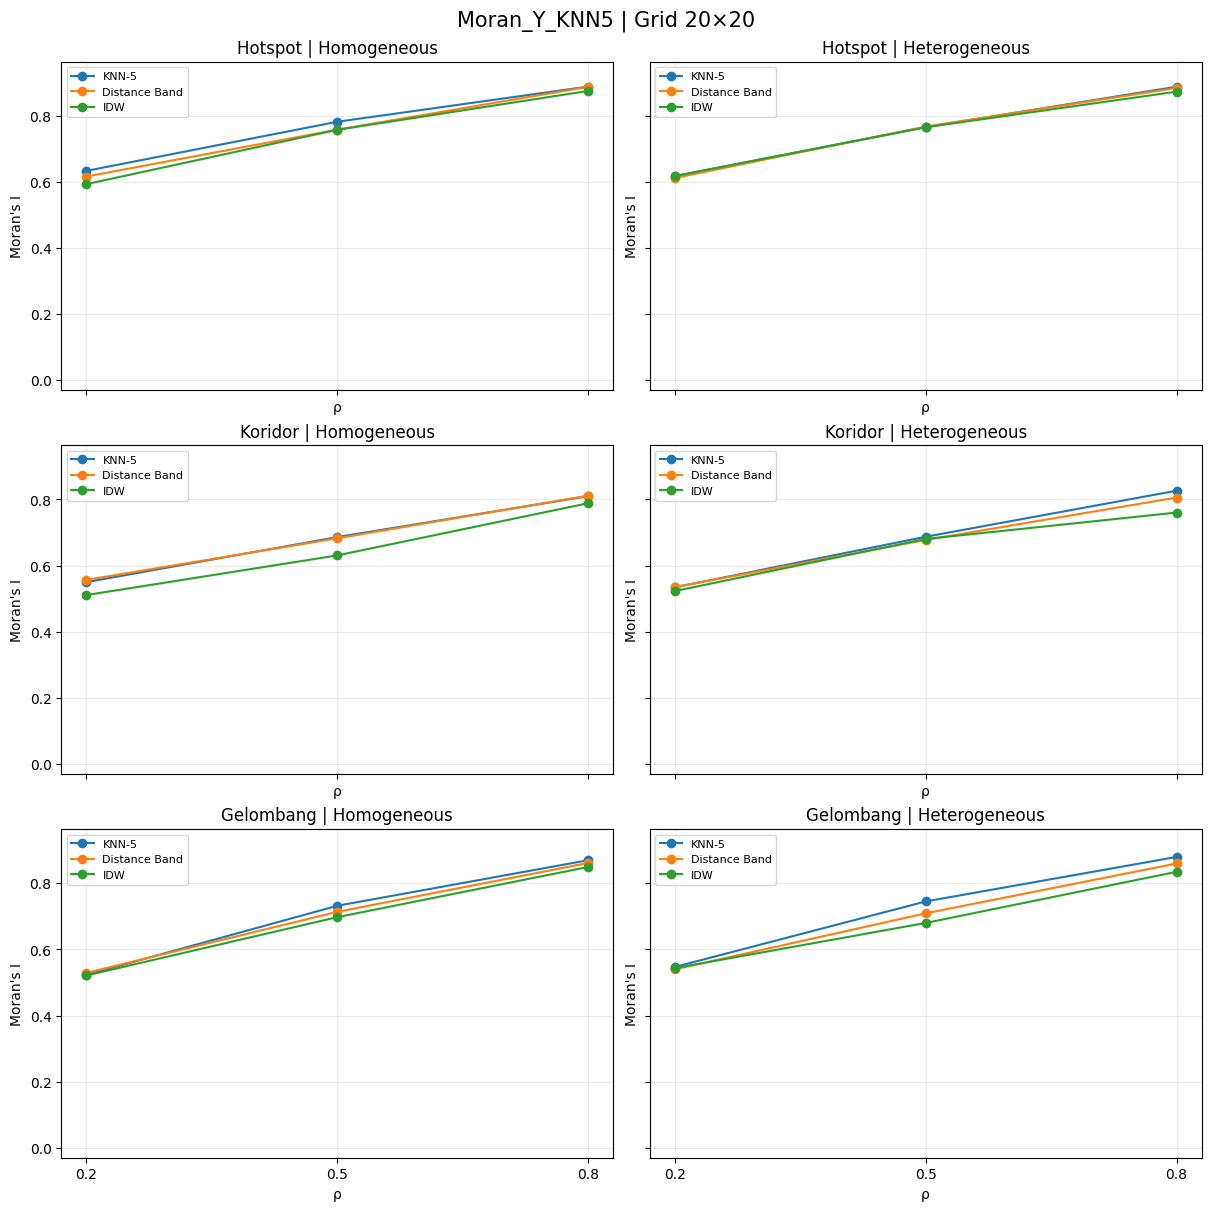

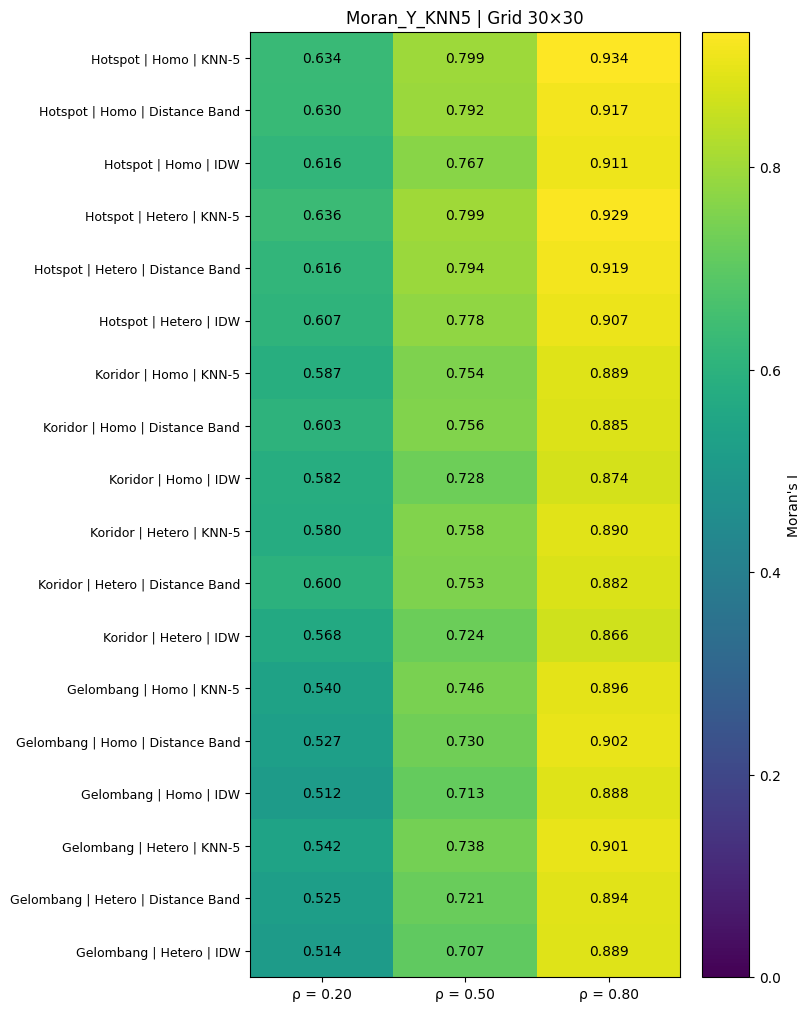

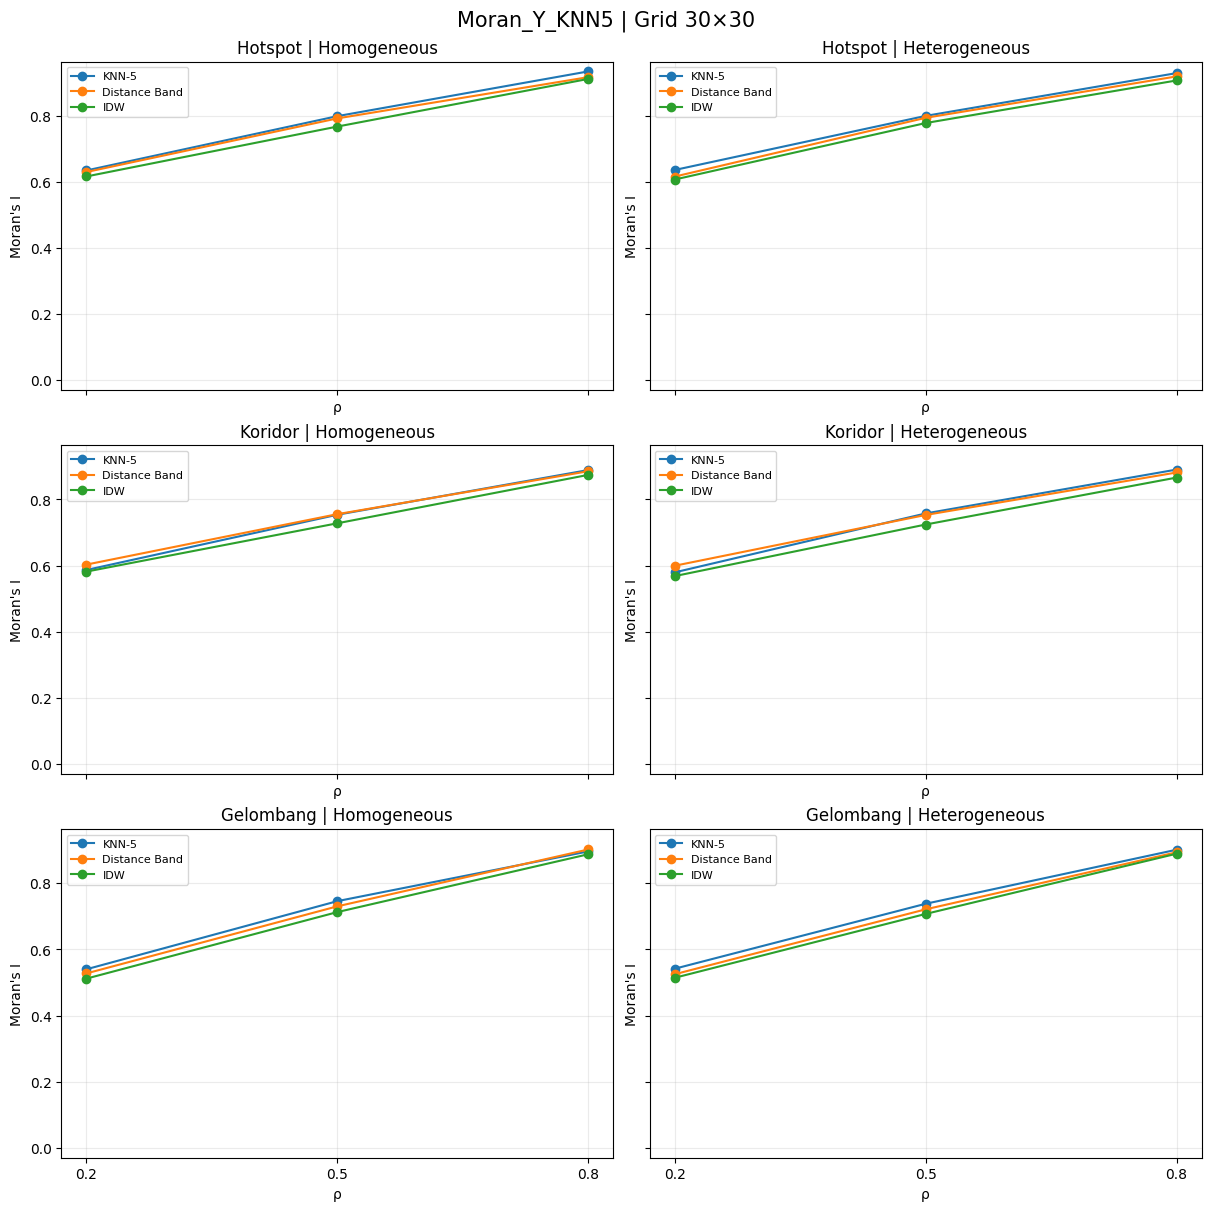

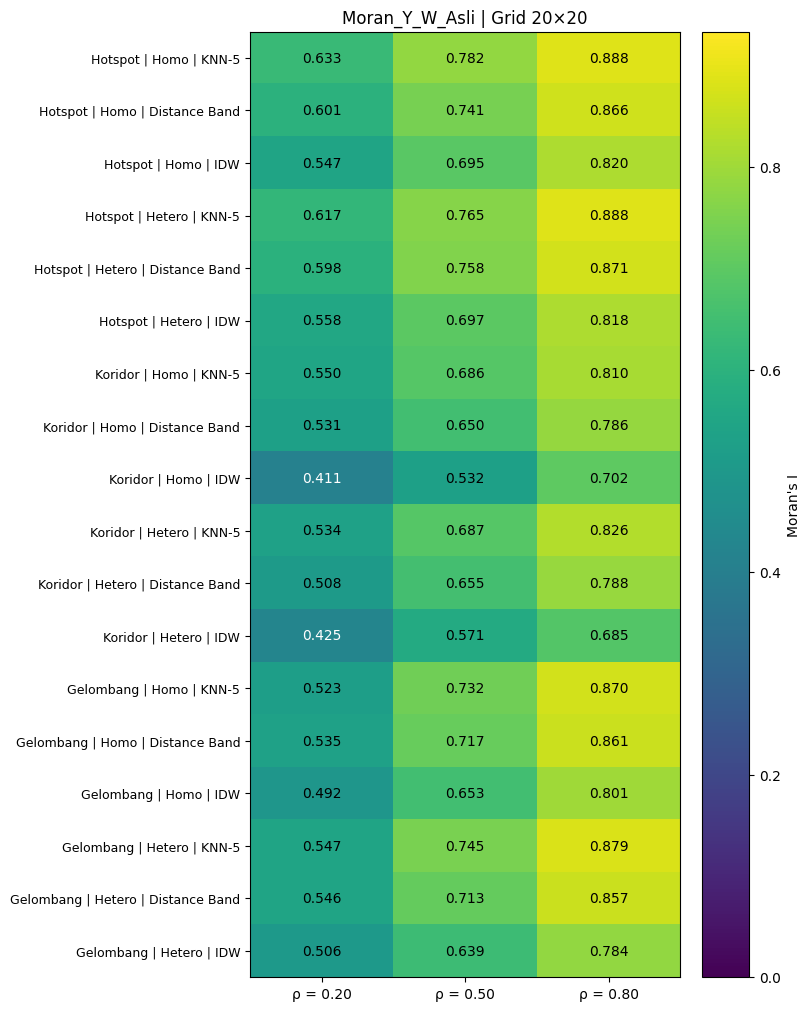

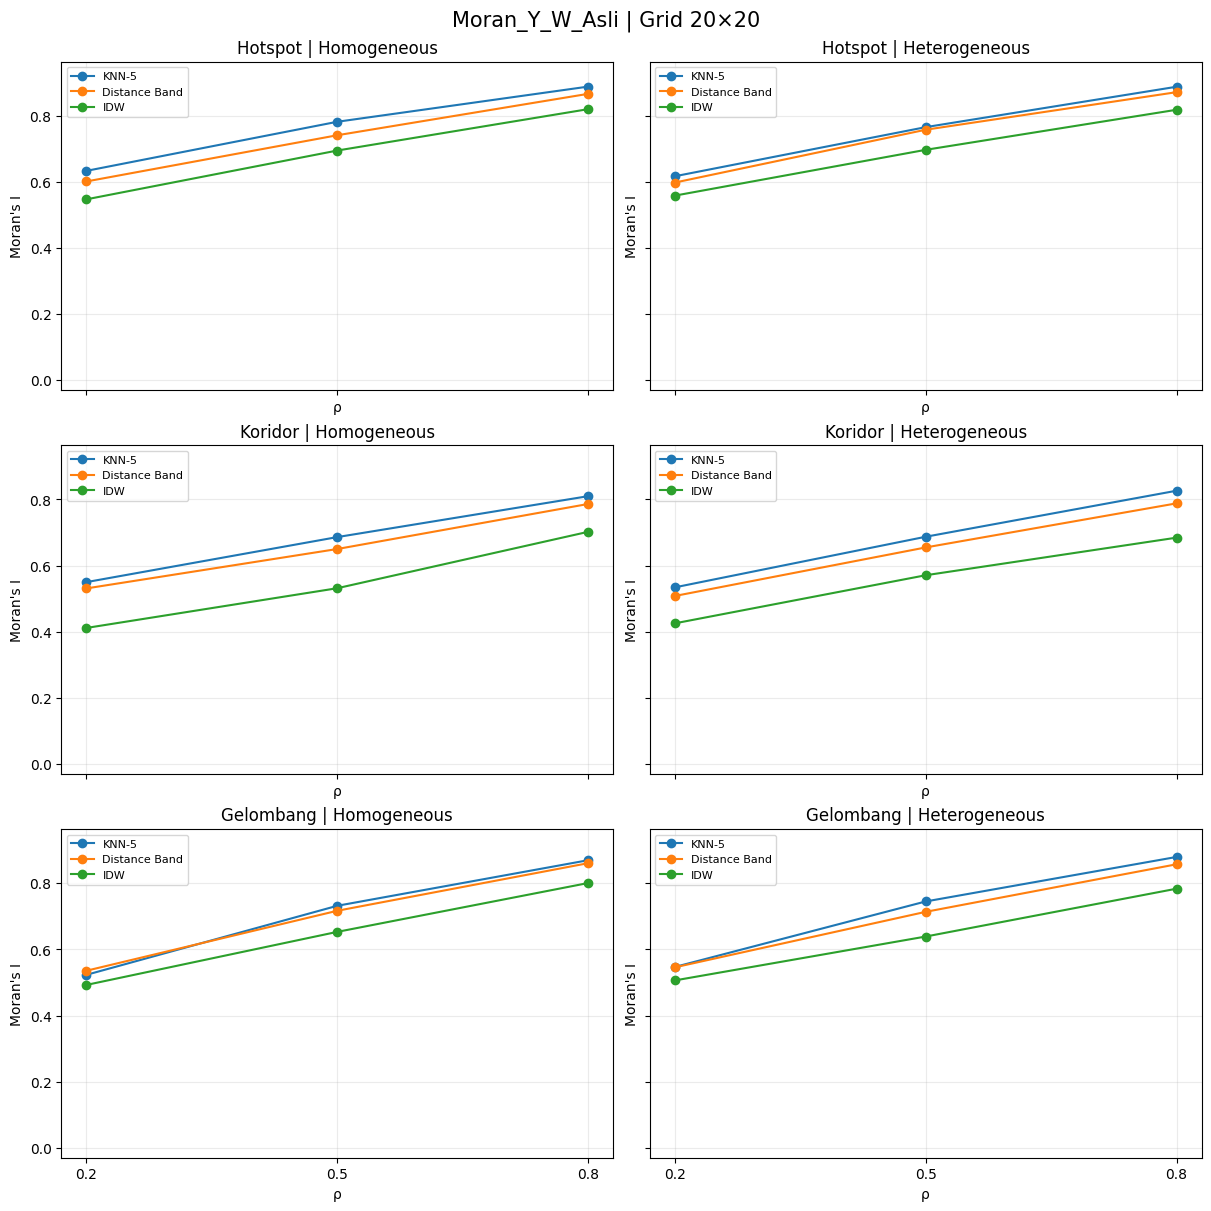

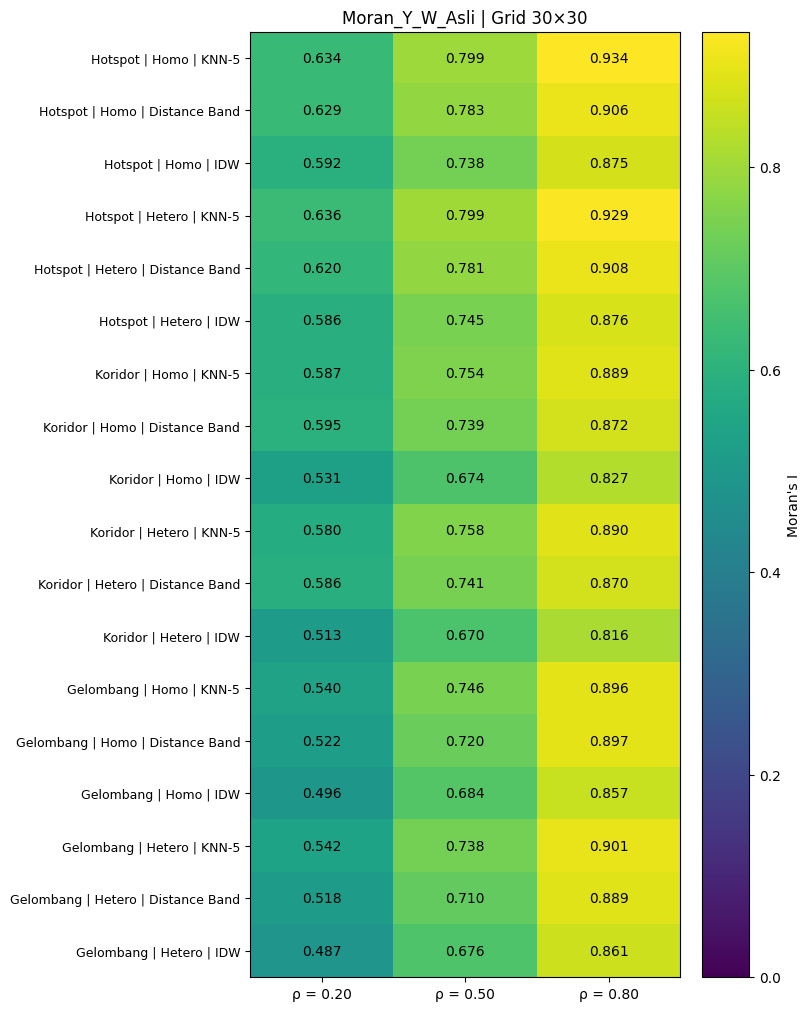

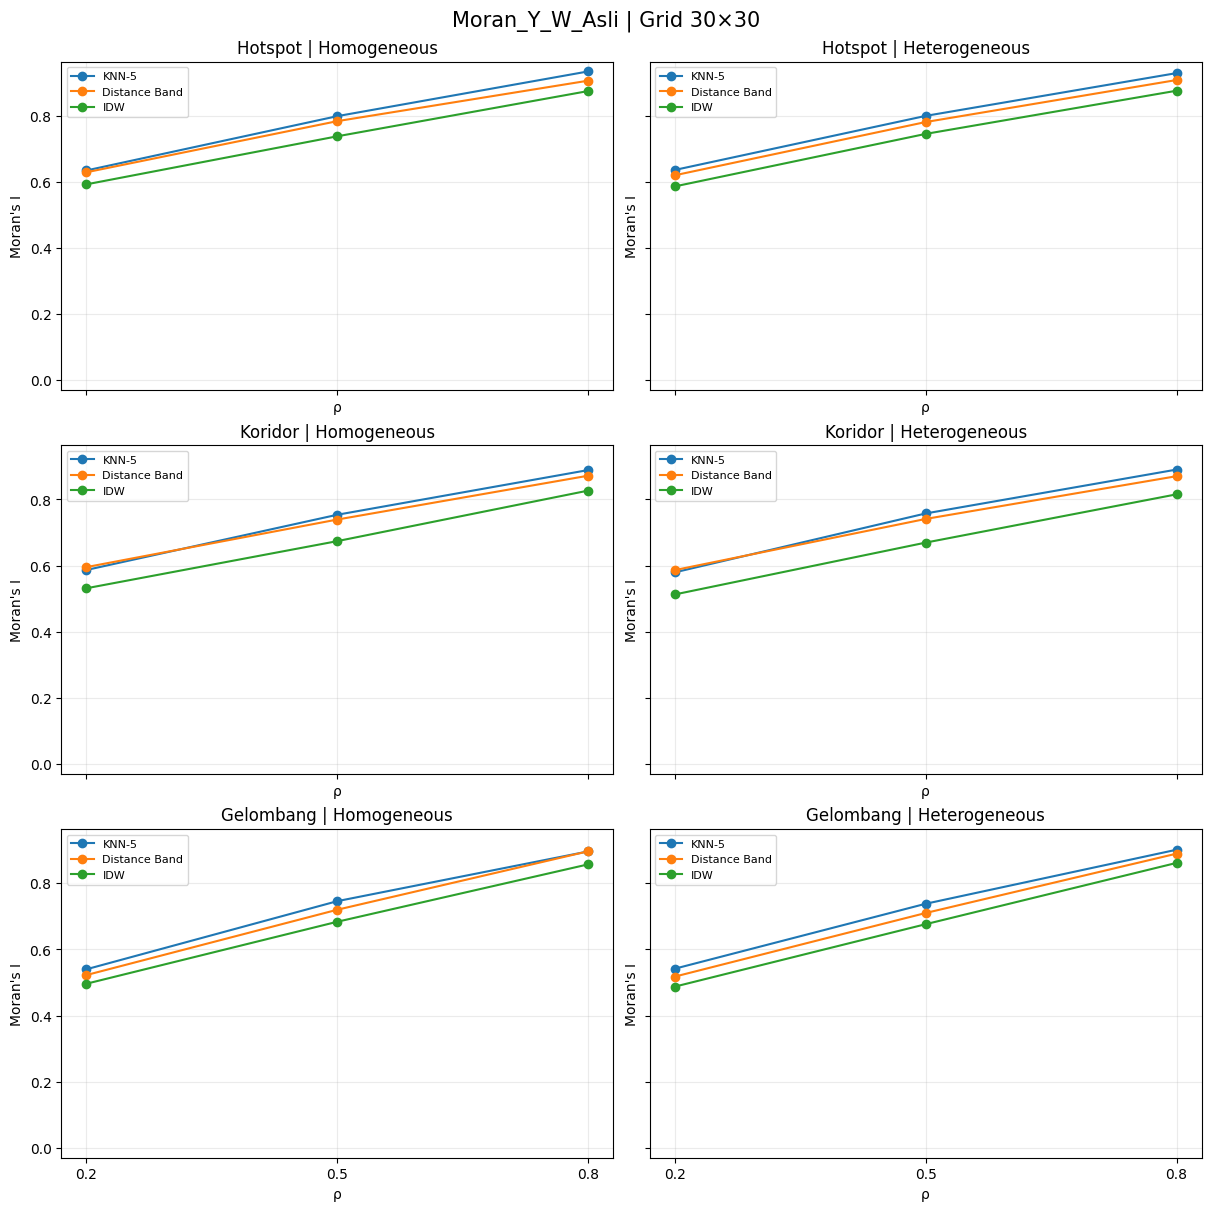

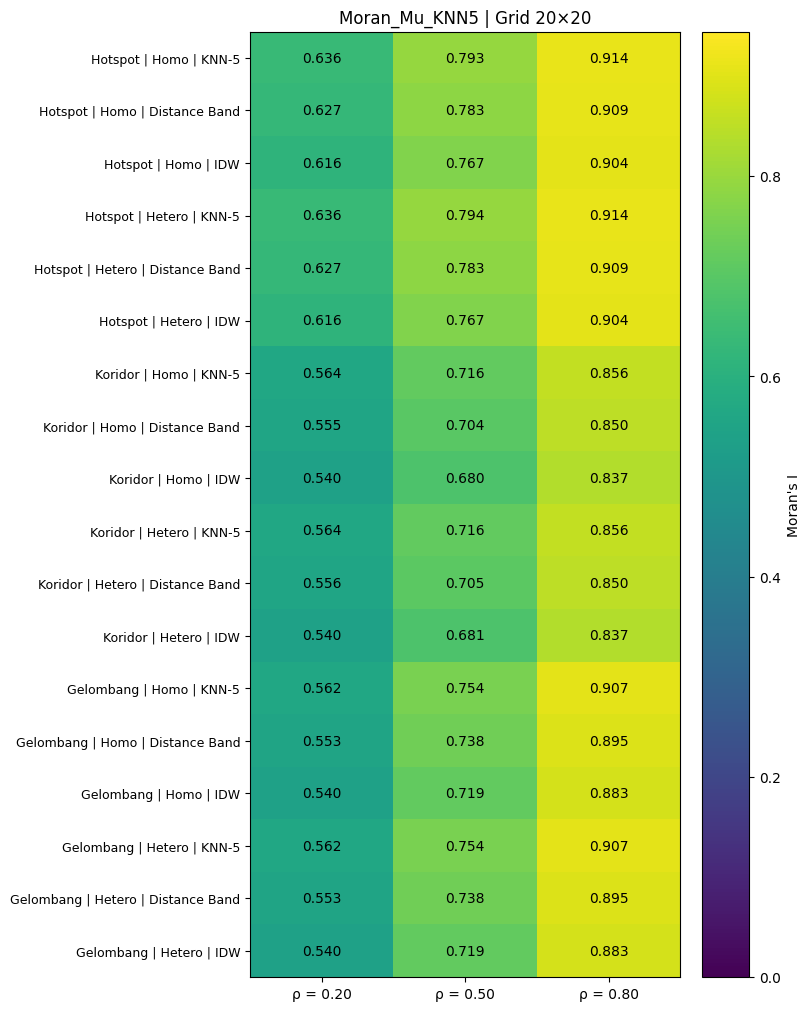

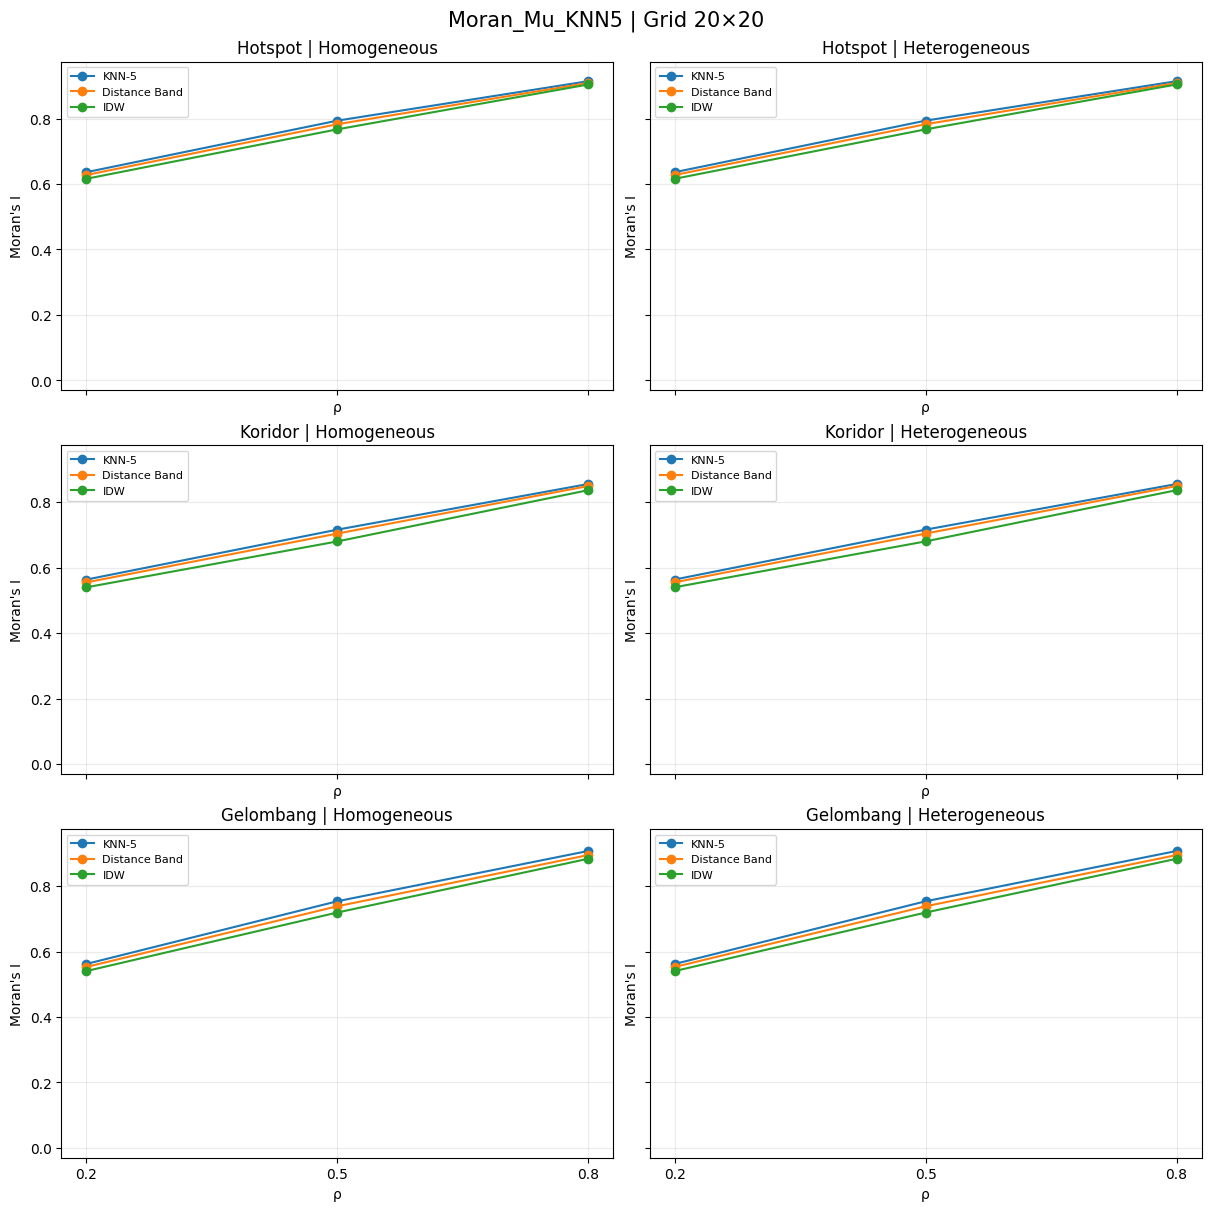

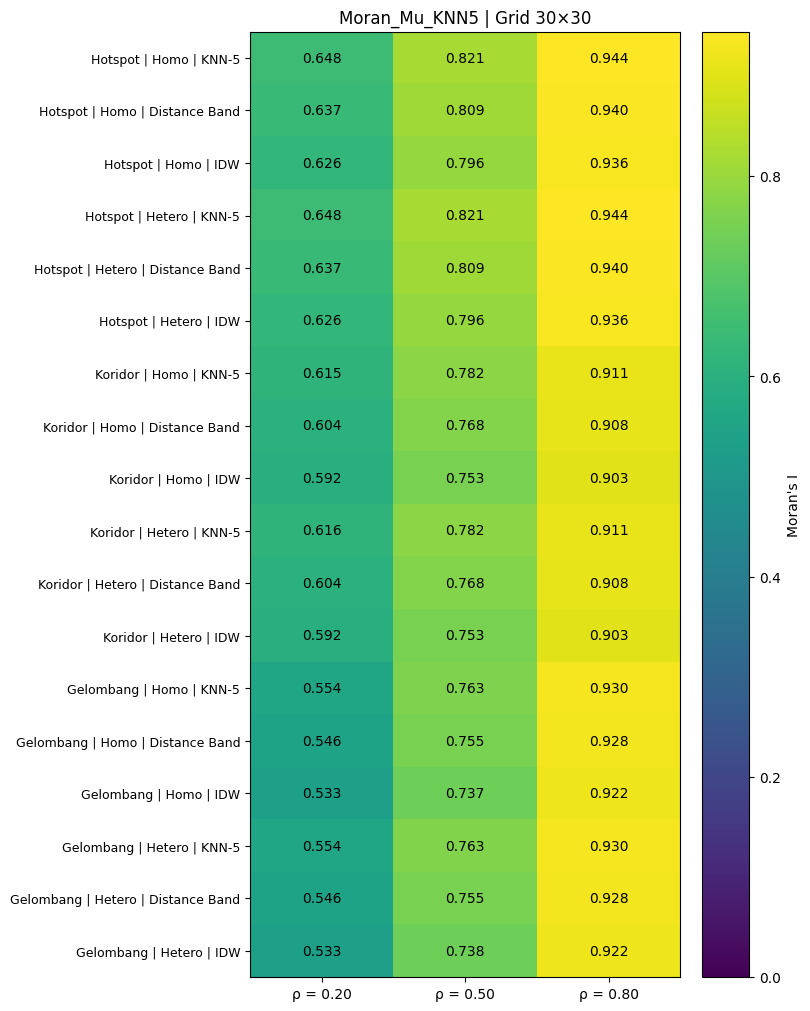

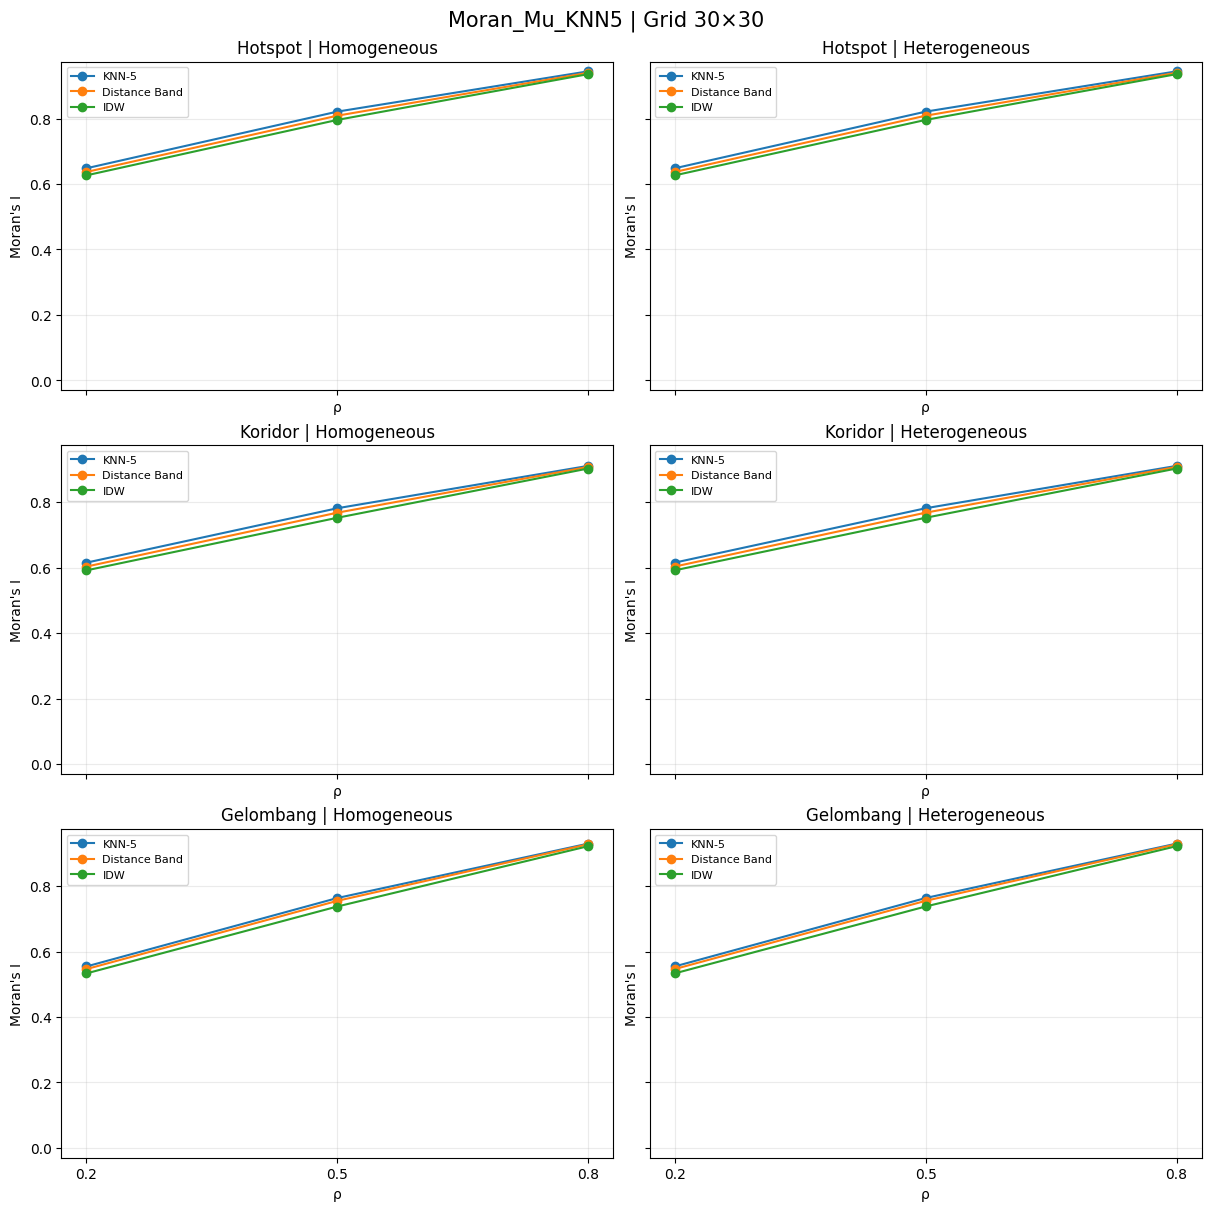

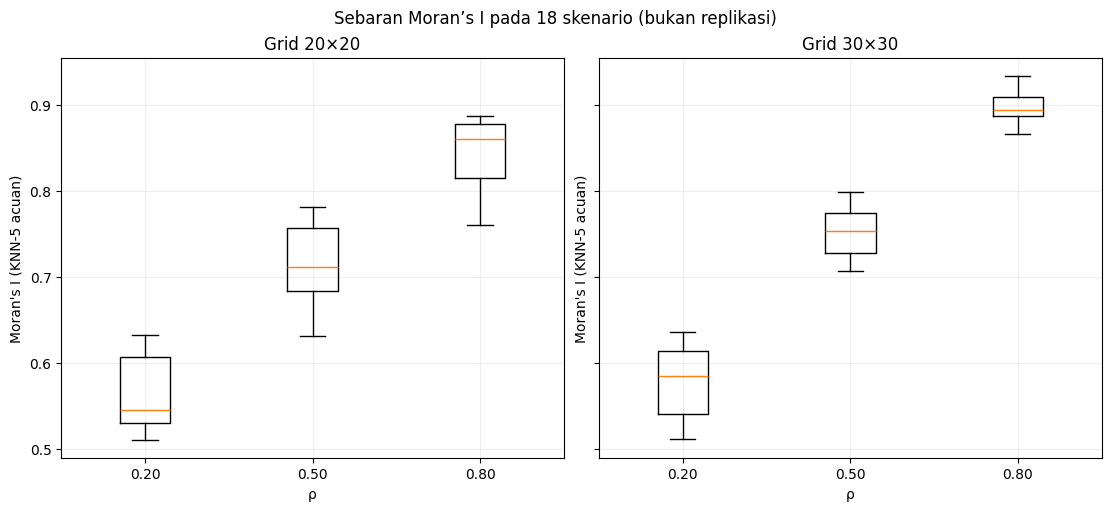

,Grid,Rho,Moran_Y_KNN5_mean,Moran_Y_KNN5_std,Moran_Y_KNN5_min,Moran_Y_KNN5_max,Moran_Y_W_Asli_mean,Moran_Y_W_Asli_std,Moran_Y_W_Asli_min,Moran_Y_W_Asli_max,Moran_Mu_KNN5_mean,Moran_Mu_KNN5_std,Moran_Mu_KNN5_min,Moran_Mu_KNN5_max
0,20,0.2,0.5612,0.0411,0.5109,0.6332,0.5369,0.0577,0.4115,0.6332,0.5771,0.0371,0.5402,0.6360
1,20,0.5,0.7175,0.0425,0.6308,0.7816,0.6898,0.0657,0.5316,0.7816,0.7395,0.0366,0.6804,0.7935
2,20,0.8,0.8473,0.0387,0.7604,0.8880,0.8222,0.0590,0.6845,0.8880,0.8838,0.0282,0.8370,0.9140
3,30,0.2,0.5787,0.0426,0.5115,0.6359,0.5664,0.0485,0.4873,0.6359,0.5951,0.0404,0.5330,0.6479
4,30,0.5,0.7531,0.0299,0.7072,0.7994,0.7363,0.0411,0.6695,0.7994,0.7760,0.0270,0.7374,0.8210
5,30,0.8,0.8985,0.0182,0.8662,0.9339,0.8829,0.0306,0.8155,0.9339,0.9245,0.0141,0.9032,0.9442


,Grid,Metrik,N_Valid,N_Naik_Konsisten,Mean_Delta_080_020
0,20,Moran_Mu_KNN5,18,18,0.3067
1,20,Moran_Y_KNN5,18,18,0.2861
2,20,Moran_Y_W_Asli,18,18,0.2853
3,30,Moran_Mu_KNN5,18,18,0.3295
4,30,Moran_Y_KNN5,18,18,0.3197
5,30,Moran_Y_W_Asli,18,18,0.3166


SELESAI — 108 kombinasi grid × rho × skenario
Folder hasil: /content/drive/MyDrive/HASIL_SIMULASI_TWEEDIE_baru/PERBANDINGAN_RHO_020_050_080_GRID20_GRID30
ZIP hasil: /content/drive/MyDrive/HASIL_SIMULASI_TWEEDIE_baru/PERBANDINGAN_RHO_020_050_080_GRID20_GRID30.zip
Catatan: Moran I tidak harus sama dengan rho; tren tidak dipaksa naik. Satu realisasi per skenario bukan uji signifikansi.


In [1]:
# ================================================================
# PERBANDINGAN RHO 0.20 / 0.50 / 0.80 — GRID20 & GRID30
# Baca ZIP Google Drive, tanpa membangkitkan ulang data.
# ================================================================
from google.colab import drive
from pathlib import Path
from io import BytesIO
import zipfile
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import display

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/HASIL_SIMULASI_TWEEDIE_baru')
OUT = ROOT / 'PERBANDINGAN_RHO_020_050_080_GRID20_GRID30'
GRIDS = [20, 30]
LEVELS = [('WEAK','020',.20), ('MODERATE','050',.50), ('STRONG','080',.80)]
RHOS = [r for _,_,r in LEVELS]
POLA = ['Hotspot','Koridor','Gelombang']
ERROR = ['Homogeneous','Heterogeneous']
METHODS = ['KNN5','DISTANCE','IDW']
SCENARIOS = [(p,e,w) for p in POLA for e in ERROR for w in METHODS]
W_LABEL = {'KNN5':'KNN-5','DISTANCE':'Distance Band','IDW':'IDW'}
SHOW = True
DPI = 180

# 1. Baca dan validasi semua sumber sebelum menyimpan grafik

def moran(x,W):
    x = np.asarray(x,float)
    z = x-x.mean()
    den = z@z
    return float(len(z)/W.sum()*(z@(W@z))/den) if den>0 else np.nan

DATA, WEIGHTS = {}, {}
for level,code,rho in LEVELS:
    stem = f'{level}_RHO{code}_SPATIAL_X_TWEEDIE_FINAL_VISUAL'
    path = ROOT / f'{stem}_ALL_GRID.zip'
    if not path.is_file():
        raise FileNotFoundError(f'ZIP belum tersedia: {path}')
    with zipfile.ZipFile(path) as z:
        for g in GRIDS:
            folder = f'SIMULASI_{stem}/GRID{g}'
            with z.open(f'{folder}/DATA_{level}_GRID{g}_RHO{code}.csv') as f:
                d = pd.read_csv(f)
            required = {'Scenario_ID','Location_ID','Rho','Pattern','Error_Structure','W_Method','Y','Mu_Tweedie','X1','X2','X3','Beta1','Beta2','Beta3'}
            if required-set(d): raise ValueError(f'{level} GRID{g}: kolom kurang {required-set(d)}')
            assert np.allclose(d.Rho,rho), (level,g,'Rho salah')
            assert d.Scenario_ID.nunique()==18
            assert len(d)==18*g*g
            assert set(d[['Pattern','Error_Structure','W_Method']].itertuples(index=False,name=None))==set(SCENARIOS)
            assert np.isfinite(d[['Y','Mu_Tweedie']]).all().all() and (d.Y>=0).all() and (d.Mu_Tweedie>0).all()
            for w in METHODS:
                W = sp.load_npz(BytesIO(z.read(f'{folder}/W_GRID{g}_{w}.npz'))).tocsr()
                assert W.shape==(g*g,g*g) and np.isfinite(W.data).all() and (W.data>=0).all()
                assert np.allclose(W.diagonal(),0) and np.allclose(np.asarray(W.sum(axis=1)).ravel(),1)
                WEIGHTS[g,rho,w]=W
            for s,part in d.groupby(['Pattern','Error_Structure','W_Method']):
                part=part.sort_values('Location_ID').reset_index(drop=True)
                assert np.array_equal(part.Location_ID,np.arange(1,g*g+1)) and part.Scenario_ID.nunique()==1
                DATA[g,rho,s]=part
    print(f'OK: {level} — GRID20 dan GRID30')

OUT.mkdir(parents=True,exist_ok=True)
rows=[]
for g in GRIDS:
    ref=WEIGHTS[g,.2,'KNN5']
    for rho in RHOS:
        for w in METHODS:
            delta=WEIGHTS[g,rho,w]-WEIGHTS[g,.2,w]
            if delta.nnz and np.max(np.abs(delta.data))>1e-10:
                raise ValueError(f'W berbeda antar rho: GRID{g}, {w}')
        for s in SCENARIOS:
            d=DATA[g,rho,s]; base=DATA[g,.2,s]
            w=WEIGHTS[g,rho,s[2]]
            rec={'Grid':g,'Rho':rho,'Pattern':s[0],'Error':s[1],'W_Method':s[2],
                 'Moran_Y_W_Asli':moran(d.Y,w),'Moran_Y_KNN5':moran(d.Y,ref),
                 'Moran_Mu_KNN5':moran(d.Mu_Tweedie,ref),'Mean_Y':d.Y.mean(),
                 'SD_Y':d.Y.std(),'Proporsi_Nol':(d.Y==0).mean(),
                 'X_Sama_dengan_Weak':np.allclose(d[['X1','X2','X3']],base[['X1','X2','X3']]),
                 'Beta_Sama_dengan_Weak':np.allclose(d[['Beta1','Beta2','Beta3']],base[['Beta1','Beta2','Beta3']])}
            if 'Moran_I_Y' in d: rec['Moran_Tersimpan_Cocok']=np.allclose(d.Moran_I_Y,rec['Moran_Y_W_Asli'],equal_nan=True)
            if 'SAR_Input' in d:
                rec['SAR_Max_Abs_Error']=np.max(np.abs(d.Mu_Tweedie.to_numpy()-rho*(w@d.Mu_Tweedie.to_numpy())-d.SAR_Input.to_numpy()))
            if 'SAR_Intercept' in d: rec['SAR_Intercept']=d.SAR_Intercept.iloc[0]
            rows.append(rec)
DIAG=pd.DataFrame(rows)
assert len(DIAG)==108
DIAG.to_csv(OUT/'01_DIAGNOSTIK_108_SKENARIO.csv',index=False)
if not DIAG[['X_Sama_dengan_Weak','Beta_Sama_dengan_Weak']].all().all():
    print('PERHATIAN: X atau beta berbeda antar rho; efek rho tidak terisolasi.')

def save(fig,path):
    fig.savefig(path,dpi=DPI,bbox_inches='tight',facecolor='white')
    if SHOW: plt.show()
    plt.close(fig)

def label(s): return f'{s[0]} | {"Homo" if s[1]=="Homogeneous" else "Hetero"} | {W_LABEL[s[2]]}'

# 2. Peta Y: per grid, per pola; 6 baris skenario x 3 kolom rho.
# Skala warna sama untuk seluruh 54 peta dalam satu grid.
# Peta tambahan mean Tweedie memakai skala sendiri, bukan skala Y.
for g in GRIDS:
    folder=OUT/f'GRID{g}'; folder.mkdir(exist_ok=True)
    for col,prefix in [('Y','02_Y'),('Mu_Tweedie','03_MU')]:
        lo=min(DATA[g,r,s][col].min() for r in RHOS for s in SCENARIOS)
        hi=max(DATA[g,r,s][col].max() for r in RHOS for s in SCENARIOS)
        norm=mpl.colors.Normalize(lo,hi if hi>lo else lo+1)
        for p in POLA:
            ss=[s for s in SCENARIOS if s[0]==p]
            fig,axes=plt.subplots(6,3,figsize=(11,19),layout='constrained')
            for i,s in enumerate(ss):
                for j,r in enumerate(RHOS):
                    ax=axes[i,j]; d=DATA[g,r,s]
                    im=ax.imshow(d[col].to_numpy().reshape(g,g),origin='lower',cmap='viridis',norm=norm,interpolation='nearest')
                    ref=WEIGHTS[g,.2,'KNN5']
                    own=moran(d[col],WEIGHTS[g,r,s[2]])
                    ax.set_title(f'ρ = {r:.2f}\nI acuan = {moran(d[col],ref):.3f} | I asli = {own:.3f}',fontsize=9)
                    if j==0: ax.set_ylabel(label(s),fontsize=9)
                    if s[1]=='Heterogeneous': ax.axvline(g/2-.5,color='white',linestyle='--',linewidth=.8)
                    ax.set_xticks([]); ax.set_yticks([])
            fig.colorbar(im,ax=axes,label=col,shrink=.65)
            fig.suptitle(f'{col} | {p} | Grid {g}×{g}\nSkala warna sama dalam grid',fontsize=15,fontweight='bold')
            save(fig,folder/f'{prefix}_{p}_GRID{g}.png')

# 3. Heatmap & garis Moran: kedua definisi W, serta mean Tweedie.
metrics=['Moran_Y_KNN5','Moran_Y_W_Asli','Moran_Mu_KNN5']
wide_rows=[]
for metric in metrics:
    vals=DIAG[metric].dropna(); lo=min(0,vals.min()) if len(vals) else -1; hi=max(.01,vals.max()) if len(vals) else 1
    # Skala heatmap dan sumbu Y sama pada kedua grid, untuk metrik yang sama.
    for g in GRIDS:
        folder=OUT/f'GRID{g}'
        sub=DIAG[DIAG.Grid==g]
        piv=sub.pivot(index=['Pattern','Error','W_Method'],columns='Rho',values=metric).reindex(SCENARIOS)[RHOS]
        for s,row in piv.iterrows():
            a,b,c=row.to_numpy(); wide_rows.append({'Grid':g,'Pattern':s[0],'Error':s[1],'W_Method':s[2],'Metrik':metric,'Rho020':a,'Rho050':b,'Rho080':c,'Delta_050_020':b-a,'Delta_080_050':c-b,'Delta_080_020':c-a,'Naik_Konsisten':bool(b>a and c>b) if np.isfinite([a,b,c]).all() else np.nan})
        fig,ax=plt.subplots(figsize=(8,10),layout='constrained')
        im=ax.imshow(piv.to_numpy(),cmap='viridis',vmin=lo,vmax=hi,aspect='auto')
        ax.set_xticks(range(3),[f'ρ = {r:.2f}' for r in RHOS]); ax.set_yticks(range(18),[label(s) for s in SCENARIOS],fontsize=9)
        for i in range(18):
            for j in range(3):
                v=piv.iloc[i,j]; ax.text(j,i,f'{v:.3f}',ha='center',va='center',color='black' if v>(lo+hi)/2 else 'white')
        fig.colorbar(im,ax=ax,label="Moran's I")
        ax.set_title(f'{metric} | Grid {g}×{g}')
        save(fig,folder/f'04_HEATMAP_{metric}_GRID{g}.png')
        fig,axes=plt.subplots(3,2,figsize=(12,12),sharex=True,sharey=True,layout='constrained')
        for i,p in enumerate(POLA):
            for j,e in enumerate(ERROR):
                ax=axes[i,j]
                for w in METHODS: ax.plot(RHOS,piv.loc[(p,e,w)].to_numpy(),marker='o',label=W_LABEL[w])
                ax.set_title(f'{p} | {e}'); ax.set_xticks(RHOS); ax.set_ylim(lo-.03,hi+.03); ax.grid(alpha=.25); ax.legend(fontsize=8)
                ax.set_xlabel('ρ'); ax.set_ylabel("Moran's I")
        fig.suptitle(f'{metric} | Grid {g}×{g}',fontsize=15)
        save(fig,folder/f'05_GARIS_{metric}_GRID{g}.png')

# 4. Ringkasan perubahan dan boxplot deskriptif
DELTA=pd.DataFrame(wide_rows)
DELTA.to_csv(OUT/'06_DELTA_MORAN_PER_SKENARIO.csv',index=False)
RINGKAS=DIAG.groupby(['Grid','Rho'])[metrics].agg(['mean','std','min','max'])
RINGKAS.columns=['_'.join(x) for x in RINGKAS.columns]; RINGKAS=RINGKAS.reset_index()
RINGKAS.to_csv(OUT/'07_RINGKASAN_MORAN.csv',index=False)
TREND=DELTA.groupby(['Grid','Metrik']).agg(N_Valid=('Naik_Konsisten','count'),N_Naik_Konsisten=('Naik_Konsisten','sum'),Mean_Delta_080_020=('Delta_080_020','mean')).reset_index()
TREND.to_csv(OUT/'08_RINGKASAN_TREN.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,5),sharey=True,layout='constrained')
for ax,g in zip(axes,GRIDS):
    sub=DIAG[DIAG.Grid==g]; groups=[sub.loc[sub.Rho==r,'Moran_Y_KNN5'].dropna() for r in RHOS]
    ax.boxplot(groups); ax.set_xticks([1,2,3],[f'{r:.2f}' for r in RHOS]); ax.set_title(f'Grid {g}×{g}'); ax.set_xlabel('ρ'); ax.set_ylabel("Moran's I (KNN-5 acuan)"); ax.grid(alpha=.2)
fig.suptitle('Sebaran Moran’s I pada 18 skenario (bukan replikasi)')
save(fig,OUT/'09_BOXPLOT_MORAN_Y_KNN5.png')
display(RINGKAS.round(4)); display(TREND.round(4))
# 5. Arsip terpisah, tanpa menimpa tiga ZIP sumber.
archive=ROOT/'PERBANDINGAN_RHO_020_050_080_GRID20_GRID30.zip'
files=sorted(p for p in OUT.rglob('*') if p.is_file())
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in files: z.write(p,p.relative_to(OUT.parent))
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    assert set(z.namelist())=={p.relative_to(OUT.parent).as_posix() for p in files}
print('SELESAI — 108 kombinasi grid × rho × skenario')
print('Folder hasil:',OUT)
print('ZIP hasil:',archive)
print('Catatan: Moran I tidak harus sama dengan rho; tren tidak dipaksa naik. Satu realisasi per skenario bukan uji signifikansi.')

